# VERDE — Dataset Analysis & Build Report (v2)
### Smart Recycling and Waste Segregation Assistant — combining four public datasets into one clean, UK-oriented training set

**Why this notebook exists.** Version 1 analysed RealWaste alone and a model trained on it scored 89% on its own test split but failed on live photos (the *domain gap*). This notebook audits four candidate sources, removes duplicates and label conflicts, merges the labels into 8 UK-oriented classes, standardises every image, and measures how different the sources really are.

**How to run (Kaggle).** Add these four inputs: `adithyachalla/waste-classification` (RealWaste), `phenomsg/waste-classification`, `sumn2u/garbage-classification-v2` (GD) and the `garbage-guru-challenge-2-0` competition. Turn **Accelerator = GPU** and **Internet = On** *before* starting the session (Section 12 downloads the MobileNetV2 weights). Then **Save & Run All**. It takes roughly 30–40 minutes.

**Outputs** (in `/kaggle/working`): `final_dataset_std.csv`, the `verde_std/` image folder (224×224 JPEG, split/class), `features_std.npy`, `dataset_card.json`.

| # | Section |
|---|---|
| 1 | [Setup, Data Sources & Inventory](#section-1) |
| 2 | [Folder Structure & Label Comparison](#section-2) |
| 3 | [Image Formats, Sizes & Shapes](#section-3) |
| 4 | [Exact Duplicates & Label Conflicts](#section-4) |
| 5 | [Designing the 8 Final Classes](#section-5) |
| 6 | [Visual Inspection](#section-6) |
| 7 | [Colour, Clutter & the Source-Shortcut Test](#section-7) |
| 8 | [Near-Duplicate Detection](#section-8) |
| 9 | [Building the Final Dataset & Split](#section-9) |
| 10 | [Standardising the Images](#section-10) |
| 11 | [Class Distribution](#section-11) |
| 12 | [Class Similarity & the Domain Gap](#section-12) |
| 13 | [Augmentation & Preprocessing Recommendations](#section-13) |
| 14 | [Limitations & Link to VERDE](#section-14) |

<a id="section-1"></a>
## Section 1: Setup, Data Sources & Inventory

**Goal:** Confirm which datasets are mounted, count their images, and build one table with a row per image (dataset, folders, format, size) that every later section reads from.

In [1]:
# ============================================================
# CELL 1 - SETUP & FIND THE MOUNTED DATASETS
# ============================================================
# WHAT: Import libraries, fix the seed, and list every dataset or competition folder
#       mounted under /kaggle/input with its image count.
# WHY:  Kaggle mounts data at paths that vary (owner/slug nesting), so we confirm the real
#       paths before scanning. The counts also give a first check against what each
#       dataset claims (for example PhenomSG's "30,000+").
# HOW:  glob finds the dataset and competition folders; rglob walks each one and counts
#       files whose extension is an image type.
# ------------------------------------------------------------------------------------

import random, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

root = Path("/kaggle/input")
candidates = sorted(root.glob("datasets/*/*")) + sorted(root.glob("competitions/*"))
for c in tqdm(candidates, desc="Counting images"):
    n = sum(1 for p in c.rglob("*") if p.suffix.lower() in IMAGE_EXTS)
    print(f"{n:>8,} images   {c}")

Counting images:  25%|██▌       | 1/4 [00:15<00:47, 15.68s/it]

   4,752 images   /kaggle/input/datasets/adithyachalla/waste-classification


Counting images:  50%|█████     | 2/4 [00:22<00:20, 10.29s/it]

   2,917 images   /kaggle/input/datasets/phenomsg/waste-classification


Counting images:  75%|███████▌  | 3/4 [01:44<00:43, 43.40s/it]

  36,777 images   /kaggle/input/datasets/sumn2u/garbage-classification-v2


Counting images: 100%|██████████| 4/4 [02:18<00:00, 34.67s/it]

  10,000 images   /kaggle/input/competitions/garbage-guru-challenge-2-0


In [2]:
# ============================================================
# CELL 2 - INVENTORY OF EVERY IMAGE IN THE CANDIDATE DATASETS
# ============================================================
# WHAT: Build one table with a row per image: dataset, folder levels, extension, file
#       size, width, height and colour mode. Save it as a CSV so later cells need no rescan.
# WHY:  Every later check (structure, sizes, duplicates, colour) reads from this table.
#       We keep the folder levels (level0/1/2) instead of guessing which one is the class,
#       because each dataset nests its folders differently. GD's paper says it ships
#       resized copies of every image (256 and 384 versions), so we skip those, or each
#       photo would be counted three times.
# HOW:  rglob finds the images; Image.open(...).size reads only the file header, so it is
#       fast. A regular expression flags GD folders named "standardized", "256" or "384".
#       The "source" column keeps the competition's train and test images apart, since
#       they are usually treated differently.
# ------------------------------------------------------------------------------------

import re

DATASETS = {
    "RealWaste": Path("/kaggle/input/datasets/adithyachalla/waste-classification"),
    "PhenomSG":  Path("/kaggle/input/datasets/phenomsg/waste-classification"),
    "GuruComp":  Path("/kaggle/input/competitions/garbage-guru-challenge-2-0"),
    "GD":        Path("/kaggle/input/datasets/sumn2u/garbage-classification-v2"),
}

GD_COPY_PATTERN = re.compile(r"standardi[sz]ed|256|384", re.IGNORECASE)

def list_images(name, root):
    paths = [p for p in root.rglob("*") if p.suffix.lower() in IMAGE_EXTS]
    if name == "GD":
        keep = [p for p in paths
                if not any(GD_COPY_PATTERN.search(part) for part in p.relative_to(root).parts[:-1])]
        print(f"GD: {len(paths):,} images found, {len(keep):,} kept "
              f"({len(paths) - len(keep):,} resized copies skipped)")
        paths = keep
    return paths

def scan_dataset(name, root):
    paths = list_images(name, root)
    rows = []
    for p in tqdm(paths, desc=f"Scanning {name}"):
        rel = list(p.relative_to(root).parts[:-1])        # folder levels below the root
        lv = rel + [""] * 3
        try:
            with Image.open(p) as img:
                w, h, mode, ok = img.size[0], img.size[1], img.mode, True
        except Exception:
            w, h, mode, ok = None, None, None, False
        rows.append({"dataset": name, "path": str(p), "rel_dir": "/".join(rel),
                     "level0": lv[0], "level1": lv[1], "level2": lv[2],
                     "ext": p.suffix.lower(), "bytes": p.stat().st_size,
                     "width": w, "height": h, "mode": mode, "readable": ok})
    return pd.DataFrame(rows)

frames = []
for name, root in DATASETS.items():
    if not root.exists():
        print(f"SKIPPED {name}: {root} not found (use the path printed by Cell 1)")
        continue
    frames.append(scan_dataset(name, root))

inv = pd.concat(frames, ignore_index=True)

# Competition data usually has separate train and test folders; keep them as separate sources
inv["source"] = inv["dataset"]
is_guru = inv["dataset"] == "GuruComp"
inv.loc[is_guru & inv["rel_dir"].str.contains("test", case=False), "source"] = "Guru-test"
inv.loc[is_guru & ~inv["rel_dir"].str.contains("test", case=False), "source"] = "Guru-train"

inv.to_csv("/kaggle/working/candidate_inventory.csv", index=False)
print(f"Total images: {len(inv):,}")
display(inv["source"].value_counts().rename("images").to_frame())

Scanning GuruComp: 100%|██████████| 10000/10000 [00:55<00:00, 178.78it/s]


GD: 36,777 images found, 12,259 kept (24,518 resized copies skipped)


Scanning GD: 100%|██████████| 12259/12259 [01:10<00:00, 172.96it/s]


Total images: 29,928


,images
source,
GD,12259
Guru-train,9000
RealWaste,4752
PhenomSG,2917
Guru-test,1000


In [3]:
# ============================================================
# CELL 2b - INSPECT THE COMPETITION FOLDER (LABELS, CSVs, README)
# ============================================================
# WHAT: List everything in the competition folder, not only images, preview any CSV files,
#       print any text/readme files, and show the folder layout of the images found in Cell 2.
# WHY:  Competition data usually keeps labels in a CSV and the test set unlabelled. We need
#       to know how labels are stored, how many images are labelled, and what the organisers
#       say about the data, before deciding whether it is usable.
# HOW:  rglob lists all files grouped by extension; read_csv previews each table and
#       value_counts shows the label columns; text files are printed up to a size limit;
#       the inventory from Cell 2 shows which folders hold the images.
# ------------------------------------------------------------------------------------

GURU = Path("/kaggle/input/competitions/garbage-guru-challenge-2-0")
files = [p for p in GURU.rglob("*") if p.is_file()]
print(f"Files in competition folder: {len(files):,}")
display(pd.Series([p.suffix.lower() for p in files]).value_counts().rename("files").to_frame())

print("Top-level contents:")
for p in sorted(GURU.iterdir()):
    n = sum(1 for q in p.rglob("*") if q.is_file()) if p.is_dir() else 1
    print(f"  {p.name}   ({n:,} files)")

print("\nImage folders (from the Cell 2 inventory):")
display(inv[inv["dataset"] == "GuruComp"]["rel_dir"].value_counts().head(15).rename("images").to_frame())

for t in [p for p in files if p.suffix.lower() in {".txt", ".md"}]:
    print(f"\n=== {t.name} ===")
    print(t.read_text(errors="ignore")[:3000])

for c in [p for p in files if p.suffix.lower() == ".csv"]:
    table = pd.read_csv(c)
    print(f"\n=== {c.name}: {table.shape[0]:,} rows x {table.shape[1]} columns ===")
    display(table.head())
    for col in table.columns:
        if table[col].dtype == object and table[col].nunique() <= 40:
            print(f"-- values in '{col}':")
            display(table[col].value_counts().to_frame())

Files in competition folder: 10,000


,files
.jpg,9979
.png,20
.jpeg,1


Top-level contents:
  dataset   (10,000 files)

Image folders (from the Cell 2 inventory):


,images
rel_dir,
dataset/train/metal,800
dataset/train/glass,800
dataset/train/biological,800
dataset/train/paper,800
dataset/train/battery,800
dataset/train/trash,800
dataset/train/cardboard,800
dataset/train/shoes,800
dataset/train/clothes,800


**Finding:** Four candidate sources were scanned: **RealWaste** 4,752 images, **PhenomSG** 2,917 (its description claims 30,000+, so the claim does not hold), the **Garbage Guru competition** 10,000 and **GD** (Garbage Classification v2) 36,777 files. GD ships three copies of every photo (original plus two resized versions), so only the 12,259 `original/` images were kept (24,518 resized copies skipped). That gives **29,928 images** to audit. The competition folder has labelled `train` (800 per class), `val` (100) and `test` (100) folders for 10 classes and no label CSV; the test folder is labelled by folder name, so it is not a hidden test set.

<a id="section-2"></a>
## Section 2: Folder Structure & Label Comparison

**Goal:** See each source's real classes and how the label vocabularies line up, because the sources do not name classes the same way.

In [4]:
# ============================================================
# CELL 3 - FOLDER STRUCTURE AND LABEL COMPARISON ACROSS SOURCES
# ============================================================
# WHAT: Show every folder in every dataset with its image count, then a table of label
#       names against sources.
# WHY:  This reveals each dataset's real classes, the class balance, and which datasets
#       share label names (GD and the competition look identical on classes). The folder
#       list also finds the extra ~1,000 competition images that Cell 2b cut off.
# HOW:  groupby on the folder path counts images per folder (the lists are short, so we
#       print them all). The label is the last folder name in lower case, and crosstab
#       counts it per source.
# ------------------------------------------------------------------------------------

display(inv.groupby("dataset").agg(images=("path", "count"),
                                   folders=("rel_dir", "nunique"),
                                   unreadable=("readable", lambda s: int((~s).sum()))))

for name, g in inv.groupby("dataset"):
    print(f"\n=== {name}: images per folder ===")
    display(g.groupby("rel_dir").size().rename("images").to_frame())

inv["label"] = inv["rel_dir"].str.split("/").str[-1].str.lower()
xt = pd.crosstab(inv["label"], inv["source"])
xt["total"] = xt.sum(axis=1)
print("\n=== Label names vs sources ===")
display(xt)

,images,folders,unreadable
dataset,,,
GD,12259,10,0
GuruComp,10000,30,0
PhenomSG,2917,18,0
RealWaste,4752,9,0



=== GD: images per folder ===


,images
rel_dir,
original/battery,756
original/biological,699
original/cardboard,1411
original/clothes,1892
original/glass,1736
original/metal,930
original/paper,1336
original/plastic,1597
original/shoes,1449



=== GuruComp: images per folder ===


,images
rel_dir,
dataset/test/battery,100
dataset/test/biological,100
dataset/test/cardboard,100
dataset/test/clothes,100
dataset/test/glass,100
dataset/test/metal,100
dataset/test/paper,100
dataset/test/plastic,100
dataset/test/shoes,100


...

,images
rel_dir,
Hazardous/Hazardous/batteries,110
Hazardous/Hazardous/e-waste,538
Hazardous/Hazardous/paints,153
Hazardous/Hazardous/pesticides,138
Non-Recyclable/Non-Recyclable/ceramic_product,138
Non-Recyclable/Non-Recyclable/diapers,145
Non-Recyclable/Non-Recyclable/platics_bags_wrappers,134
Non-Recyclable/Non-Recyclable/sanitary_napkin,110
Non-Recyclable/Non-Recyclable/stroform_product,118



=== RealWaste: images per folder ===


,images
rel_dir,
1-Cardboard,461
2-Food Organics,411
3-Glass,420
4-Metal,790
5-Miscellaneous Trash,495
6-Paper,500
7-Plastic,921
8-Textile Trash,318
9-Vegetation,436



=== Label names vs sources ===


source,GD,Guru-test,Guru-train,PhenomSG,RealWaste,total
label,,,,,,
1-cardboard,0,0,0,0,461,461
2-food organics,0,0,0,0,411,411
3-glass,0,0,0,0,420,420
4-metal,0,0,0,0,790,790
5-miscellaneous trash,0,0,0,0,495,495
6-paper,0,0,0,0,500,500
7-plastic,0,0,0,0,921,921
8-textile trash,0,0,0,0,318,318
9-vegetation,0,0,0,0,436,436


**Finding:** The label vocabularies differ completely. RealWaste has **9** classes (Cardboard, Food Organics, Glass, Metal, Miscellaneous Trash, Paper, Plastic, Textile Trash, Vegetation). GD and the competition use the **same 10 names** (battery, biological, cardboard, clothes, glass, metal, paper, plastic, shoes, trash), a first hint that they share an origin. PhenomSG has **18** sub-folders under four broad groups (Hazardous, Non-Recyclable, Organic, Recyclable). Battery and electrical items appear only in GD/competition (`battery`) and PhenomSG (`batteries`, `e-waste`, `paints`, `pesticides`); RealWaste has none. The sources therefore cannot be merged by name; they need an explicit mapping (Section 5). All image headers were readable at this stage (4 images later failed full decoding, Section 8).

<a id="section-3"></a>
## Section 3: Image Formats, Sizes & Shapes

**Goal:** Check whether the sources differ in file type, resolution, aspect ratio and file size, because such differences can act as a hidden clue that tells a model which dataset an image came from.

,images,main_ext,width_min,width_median,width_max,height_median,pct_square,unique_sizes,avg_file_kb
source,,,,,,,,,
GD,12259,.jpg,51,400.0,7786,384.0,18.0,2407,42.0
Guru-test,1000,.jpg,83,310.5,4056,292.0,19.6,357,36.6
Guru-train,8000,.jpg,51,320.0,7786,299.0,20.4,1425,40.5
Guru-val,1000,.jpg,83,313.5,3024,280.0,18.9,346,31.5
PhenomSG,2917,.jpg,200,1024.0,7800,736.0,11.3,1542,361.1
RealWaste,4752,.jpg,524,524.0,524,524.0,100.0,1,141.5


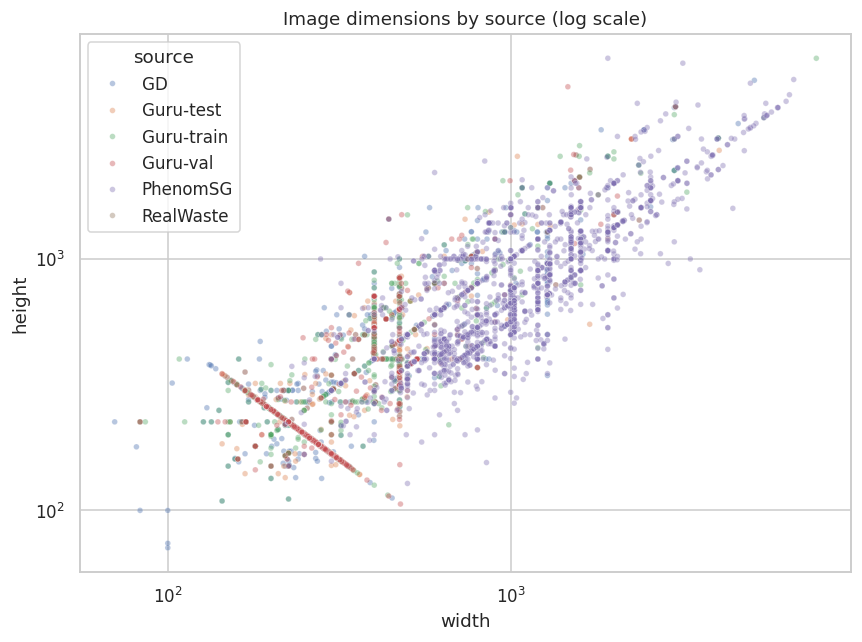

In [5]:
# ============================================================
# CELL 4 - IMAGE FORMATS, SIZES AND SHAPES PER SOURCE
# ============================================================
# WHAT: Compare file type, resolution, aspect ratio and file size across the sources, and
#       plot width against height.
# WHY:  Different formats and sizes (for example 256x256 JPEG vs 524x524 JPEG) can act as a
#       hidden clue that tells the model which dataset an image came from. We need to know
#       the differences before deciding how to standardise.
# HOW:  groupby/agg builds the comparison table; the scatter uses a sample per source so the
#       plot stays readable. A first line splits the competition's val images from its
#       train images, which Cell 2 had merged.
# ------------------------------------------------------------------------------------

inv.loc[(inv["dataset"] == "GuruComp") & inv["rel_dir"].str.contains("/val/"), "source"] = "Guru-val"

inv["aspect"] = (inv["width"] / inv["height"]).round(2)
inv["size_wh"] = inv["width"].fillna(0).astype(int).astype(str) + "x" + inv["height"].fillna(0).astype(int).astype(str)

props = inv.groupby("source").agg(
    images=("path", "count"),
    main_ext=("ext", lambda s: s.value_counts().index[0]),
    width_min=("width", "min"), width_median=("width", "median"), width_max=("width", "max"),
    height_median=("height", "median"),
    pct_square=("aspect", lambda s: round((s == 1.0).mean() * 100, 1)),
    unique_sizes=("size_wh", "nunique"),
    avg_file_kb=("bytes", lambda s: round(s.mean() / 1024, 1)),
)
display(props)

samp = inv.groupby("source", group_keys=False).apply(lambda g: g.sample(min(2000, len(g)), random_state=SEED))
plt.figure(figsize=(8, 6))
sns.scatterplot(data=samp, x="width", y="height", hue="source", alpha=0.4, s=14)
plt.xscale("log"); plt.yscale("log")
plt.title("Image dimensions by source (log scale)")
plt.tight_layout()
plt.show()

**Finding:** The sources are technically very different. **RealWaste** is uniform: every image is 524×524 JPEG (1 unique size, ~141 KB). **GD** and the competition are small and irregular (median width ~310–400 px, only ~19–20% square, hundreds to ~2,400 distinct sizes, 31–42 KB). **PhenomSG** is large (median 1024×736, ~361 KB, only 11% square). The competition's validation images lie on one diagonal in the scatter plot, a fixed-area resize that is a processing fingerprint of that split. Differences this large are a shortcut risk (quantified in Section 7), so every image will be standardised to one format and size in Section 10.

<a id="section-4"></a>
## Section 4: Exact Duplicates & Label Conflicts

**Goal:** Find byte-identical files within and across sources, and check whether the same image carries different labels.

In [6]:
# ============================================================
# CELL 5 - EXACT DUPLICATES (WITHIN AND ACROSS DATASETS)
# ============================================================
# WHAT: Find byte-identical images, and report which sources they sit in.
# WHY:  Identical files across sources mean the same photo could land in both train and
#       test, which inflates accuracy. We especially want to know whether the competition
#       overlaps GD, and whether its own train, val and test folders overlap each other.
# HOW:  Two identical files must have the same byte size, so we hash only files whose size
#       collides with another file. This catches exact copies only; re-saved or resized
#       copies need perceptual hashing, which can come next if this shows little overlap
#       between datasets that clearly share a source.
# ------------------------------------------------------------------------------------

cand = inv[inv.duplicated("bytes", keep=False)].copy()
print(f"Files sharing a byte size with another file: {len(cand):,} (these get hashed)")

tqdm.pandas(desc="Hashing")
cand["md5"] = cand["path"].progress_apply(lambda p: hashlib.md5(Path(p).read_bytes()).hexdigest())

dups = cand[cand.duplicated("md5", keep=False)]
groups = dups.groupby("md5").agg(files=("path", "count"),
                                 sources=("source", lambda s: " + ".join(sorted(set(s)))),
                                 labels=("label", lambda s: " / ".join(sorted(set(s)))))
print(f"Exact-duplicate groups: {len(groups):,}  |  files involved: {len(dups):,}")
display(groups["sources"].value_counts().rename("groups").to_frame())
print("Sample groups where the same image carries different label names:")
display(groups[groups["labels"].str.contains("/")].head(15))

Files sharing a byte size with another file: 16,666 (these get hashed)


Hashing: 100%|██████████| 16666/16666 [00:17<00:00, 963.39it/s]


Exact-duplicate groups: 6,886  |  files involved: 13,775


,groups
sources,
GD + Guru-train,5267
GD + Guru-test,648
GD + Guru-val,628
PhenomSG,282
Guru-train + RealWaste,48
Guru-test + RealWaste,6
Guru-val + RealWaste,6
Guru-train,1


Sample groups where the same image carries different label names:


,files,sources,labels
md5,,,
00464e87f4162cd07983e05a6c02ed6b,2,Guru-test + RealWaste,5-miscellaneous trash / trash
0046ba50a4f8df3414872f3a19c74d45,2,Guru-train + RealWaste,5-miscellaneous trash / trash
0531bf0a6cf9aa2ef7d5456597f1bb3c,2,Guru-train + RealWaste,5-miscellaneous trash / trash
074bf40a86242bf1e5a7c235ad42dd8d,2,Guru-val + RealWaste,5-miscellaneous trash / trash
07fba99442213a025e3d572c774d3b2f,2,Guru-train + RealWaste,5-miscellaneous trash / trash
0991baff5229a01fc80f1c1b9c5ff56c,2,Guru-train + RealWaste,5-miscellaneous trash / trash
0c4643dea041994d715ccd8df20079e9,2,Guru-train + RealWaste,5-miscellaneous trash / trash
1366f99c938322077eac28712b1d91bc,2,PhenomSG,food_scraps / kitchen_waste
1396b194239da39280093221a4a02520,2,Guru-test + RealWaste,5-miscellaneous trash / trash


In [7]:
# ============================================================
# CELL 5b - REMOVE EXACT DUPLICATES AND CHECK FOR LABEL CONFLICTS
# ============================================================
# WHAT: Give every image a duplicate-group ID, keep one copy per group, drop any group whose
#       copies carry conflicting labels, and count what is left per class and source.
# WHY:  Cell 5 showed that about 65% of the competition images are copies of GD images, so
#       the raw count of 29,928 overstates the data. The number of distinct images, and
#       which source each class really comes from, decides whether merging is worth it.
#       Copies with conflicting labels cannot be trusted at all.
# HOW:  The MD5 hashes from Cell 5 are attached to the inventory (files with a unique byte
#       size cannot have a copy, so they get their own ID). A provisional label-to-concept
#       table lets us compare labels named differently across datasets (for example "trash"
#       and "5-miscellaneous trash"). It is not the final class mapping. Where copies exist
#       in several sources we keep the highest-priority one: RealWaste, GD, competition,
#       PhenomSG.
# ------------------------------------------------------------------------------------

CONCEPT = {
    # RealWaste
    "1-cardboard": "cardboard", "2-food organics": "food", "3-glass": "glass", "4-metal": "metal",
    "5-miscellaneous trash": "general", "6-paper": "paper", "7-plastic": "plastic",
    "8-textile trash": "textile", "9-vegetation": "garden",
    # GD and the competition
    "battery": "battery", "biological": "organic", "cardboard": "cardboard", "clothes": "textile",
    "glass": "glass", "metal": "metal", "paper": "paper", "plastic": "plastic",
    "shoes": "textile", "trash": "general",
    # PhenomSG
    "batteries": "battery", "e-waste": "electricals", "paints": "hazardous", "pesticides": "hazardous",
    "ceramic_product": "general", "diapers": "general", "platics_bags_wrappers": "plastic_film",
    "sanitary_napkin": "general", "stroform_product": "general", "coffee_tea_bags": "food",
    "egg_shells": "food", "food_scraps": "food", "kitchen_waste": "food", "yard_trimmings": "garden",
    "cans_all_type": "metal", "glass_containers": "glass", "paper_products": "paper",
    "plastic_bottles": "plastic",
}

inv = inv.drop(columns=["md5"], errors="ignore").merge(cand[["path", "md5"]], on="path", how="left")
inv["md5"] = inv["md5"].fillna(pd.Series("unique_" + inv.index.astype(str), index=inv.index))
inv["concept"] = inv["label"].map(CONCEPT)
print("Labels with no concept (should be empty):", list(inv.loc[inv["concept"].isna(), "label"].unique()))

# --- Duplicate groups and label conflicts ---
groups = inv.groupby("md5").agg(copies=("path", "count"),
                                sources=("source", lambda s: " + ".join(sorted(set(s)))),
                                concepts=("concept", lambda s: tuple(sorted(set(s)))))
conflicts = groups[groups["concepts"].map(len) > 1]
print(f"Duplicate groups with conflicting labels: {len(conflicts):,}")
if len(conflicts):
    display(conflicts["concepts"].astype(str).value_counts().head(10).rename("groups").to_frame())

# --- Keep one copy per group, skipping conflicted groups ---
PRIORITY = {"RealWaste": 0, "GD": 1, "Guru-train": 2, "Guru-val": 3, "Guru-test": 4, "PhenomSG": 5}
inv["prio"] = inv["source"].map(PRIORITY)
clean = inv[~inv["md5"].isin(conflicts.index)]
uniq = clean.sort_values("prio").drop_duplicates("md5", keep="first").copy()
uniq["src"] = uniq["source"].replace({"Guru-train": "Competition-only",
                                      "Guru-val": "Competition-only",
                                      "Guru-test": "Competition-only"})

print(f"Images before: {len(inv):,}  |  copies in conflicted groups dropped: {len(inv) - len(clean):,}"
      f"  |  distinct images kept: {len(uniq):,}")
display(pd.crosstab(uniq["concept"], uniq["src"], margins=True, margins_name="total"))
uniq.to_csv("/kaggle/working/candidate_unique.csv", index=False)

Labels with no concept (should be empty): []
Duplicate groups with conflicting labels: 7


,groups
concepts,
"('general', 'plastic_film')",2
"('general', 'glass')",2
"('electricals', 'food')",1
"('general', 'paper')",1
"('general', 'metal')",1


Images before: 29,928  |  copies in conflicted groups dropped: 15  |  distinct images kept: 23,032


src,Competition-only,GD,PhenomSG,RealWaste,total
concept,,,,,
battery,243,756,110,0,1109
cardboard,249,1411,0,461,2121
electricals,0,0,267,0,267
food,0,0,537,411,948
garden,0,0,131,436,567
general,508,453,505,495,1961
glass,441,1736,138,420,2735
hazardous,0,0,291,0,291
metal,179,930,270,790,2169


**Finding:** There are **6,886 exact-duplicate groups (13,775 files)**. Almost all are **GD ↔ competition** (5,267 with competition train, 648 with test, 628 with val), so the competition is largely a re-split of GD and is **not independent data**. Another **60 groups** are competition ↔ RealWaste (the competition contains RealWaste's own photos, labelled `trash`), and 282 are inside PhenomSG. Seven duplicate groups carry conflicting labels (for example `5-miscellaneous trash` vs `trash`, or `food_scraps` vs `kitchen_waste`); their 15 copies were dropped. After removing exact copies **23,032 distinct images** remain from 29,928. If these duplicates had been left in, the same photo could sit in both training and test and inflate every score.

<a id="section-5"></a>
## Section 5: Designing the 8 Final Classes

**Goal:** Map the 37 source label names into a small set of classes that match what the user actually does with the item in England, so a classification error is not "paper vs cardboard" (same bin) but a real mistake.

| Final class | Source labels merged | Why |
|---|---|---|
| `paper_card` | paper, cardboard, paper_products | same household collection |
| `plastic` | plastic, plastic_bottles, plastic bags/wrappers | rigid plastic and film (film collections are being phased in for England) |
| `glass` | glass, glass_containers | |
| `metal` | metal, cans_all_type | |
| `food_garden` | food organics, vegetation, biological, food scraps, kitchen waste, coffee/tea bags, egg shells, yard trimmings | food and garden waste are collected as organic streams |
| `textile` | clothes, shoes, textile trash | textile banks / reuse; whether an item is clean enough is decided in the advice step, not by the classifier (see Section 9) |
| `special` | battery, e-waste, paints, pesticides | not for household bins; take to a collection point |
| `general` | trash, miscellaneous trash, ceramics, diapers, sanitary products, polystyrene | residual waste |

*The mapping follows the England household rules ("Simpler Recycling"); councils differ, so the app's advice must stay a suggestion that links to the local council.*

In [8]:
# ============================================================
# CELL 5c - MERGE SIMILAR CONCEPTS INTO THE 8 FINAL CLASSES
# ============================================================
# WHAT: Map each provisional concept to a final class, keeping the original concept as a
#       sub-label, and show the new class sizes per source.
# WHY:  Several concepts had a single source or a boundary the UK bins ignore (paper vs
#       card, food vs garden, battery vs e-waste). Merging them avoids errors that cost the
#       user nothing and removes thin, source-specific classes.
# HOW:  A dictionary maps concept -> final class; the original "concept" column stays so
#       paper-vs-cardboard can still be analysed. The imbalance ratio is the largest class
#       over the smallest.
# ------------------------------------------------------------------------------------

FINAL = {
    "paper": "paper_card", "cardboard": "paper_card",
    "glass": "glass", "metal": "metal",
    "plastic": "plastic", "plastic_film": "plastic",
    "food": "food_garden", "garden": "food_garden", "organic": "food_garden",
    "textile": "textile",
    "battery": "special", "electricals": "special", "hazardous": "special",
    "general": "general",
}

uniq["final_class"] = uniq["concept"].map(FINAL)
print("Concepts with no final class (should be empty):", list(uniq.loc[uniq["final_class"].isna(), "concept"].unique()))

xt = pd.crosstab(uniq["final_class"], uniq["src"], margins=True, margins_name="total")
display(xt.sort_values("total", ascending=False))

sizes = uniq["final_class"].value_counts()
print(f"Imbalance ratio (largest / smallest): {sizes.max() / sizes.min():.2f}x")
uniq.to_csv("/kaggle/working/candidate_unique.csv", index=False)

Concepts with no final class (should be empty): []


src,Competition-only,GD,PhenomSG,RealWaste,total
final_class,,,,,
total,3396,12259,2625,4752,23032
textile,915,3341,0,318,4574
paper_card,510,2747,118,961,4336
plastic,253,1597,258,921,3029
glass,441,1736,138,420,2735
food_garden,347,699,668,847,2561
metal,179,930,270,790,2169
general,508,453,505,495,1961
special,243,756,668,0,1667


Imbalance ratio (largest / smallest): 2.74x


**Finding:** Merging 14 provisional concepts into **8 classes** gives a largest/smallest ratio of **2.74×** before any balancing. Two merges were chosen on purpose: paper and cardboard (they share a bin, and version 1's confusion matrix showed Cardboard being mistaken for Paper) and the three "hazardous" concepts (batteries, electricals, paints/pesticides all mean "not for the bin"). `special` is the thinnest class and, importantly, **no RealWaste image belongs to it**.

<a id="section-6"></a>
## Section 6: Visual Inspection

**Goal:** Look at real, de-duplicated samples per concept and source. Numbers cannot show what an image *looks like*, and the sources were collected very differently.

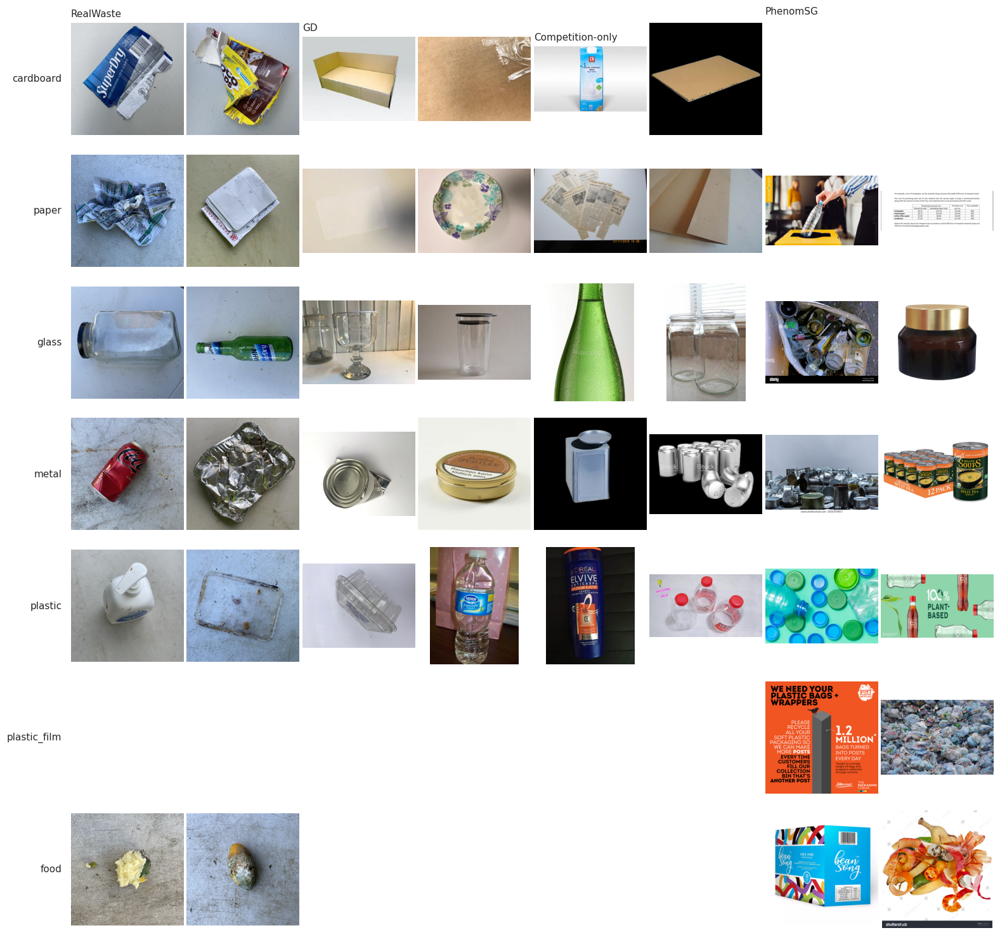

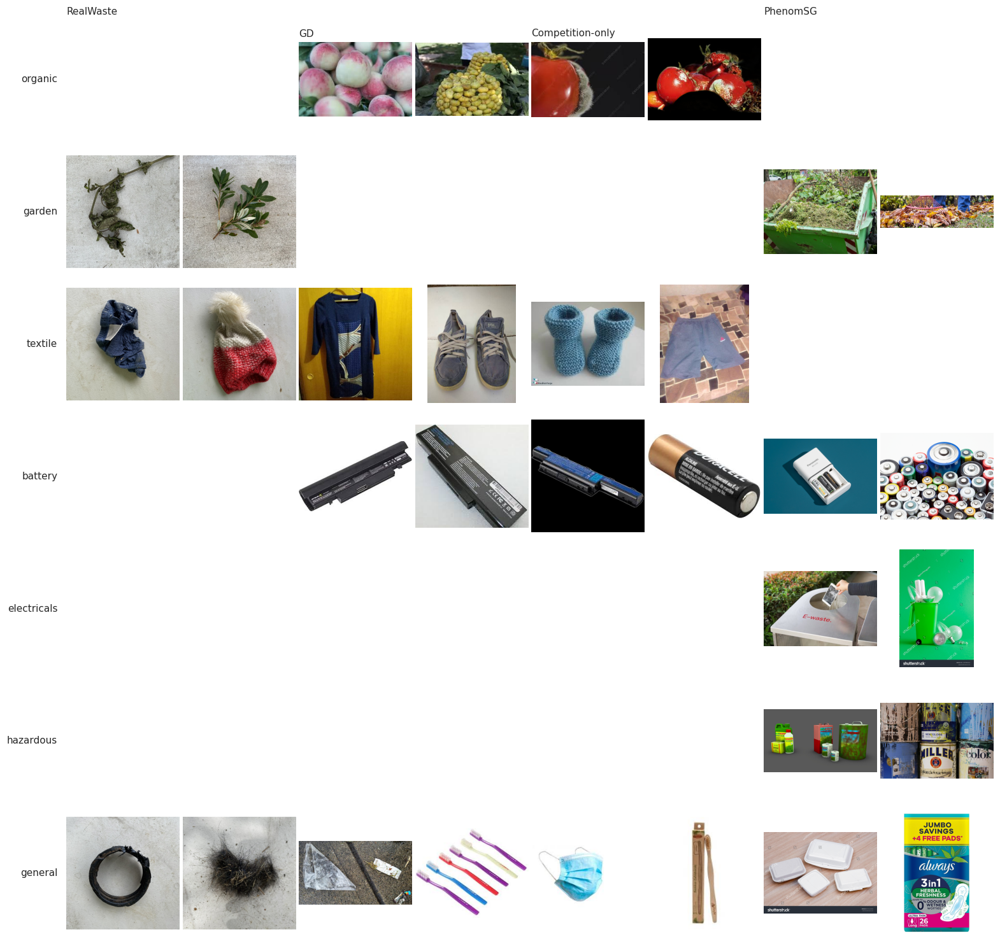

In [9]:
# ============================================================
# CELL 6 - SAMPLE IMAGES PER CONCEPT AND SOURCE (DE-DUPLICATED)
# ============================================================
# WHAT: For each provisional concept, show 2 random images from each source that has it.
# WHY:  Folder names can hide what is inside. We need to see whether "organic" is food or
#       garden, whether "plastic" mixes bottles with bags, whether "trash" is a coherent
#       class, and how different the sources look for the same concept.
# HOW:  A seeded random generator picks images from the de-duplicated table (uniq). Row
#       labels are drawn with ax.text and column headers with set_title, because axis("off")
#       would hide a y-label.
# ------------------------------------------------------------------------------------

SRC_ORDER = ["RealWaste", "GD", "Competition-only", "PhenomSG"]

def plot_concept_grid(concepts, n_per_source=2, seed=SEED):
    rng = np.random.default_rng(seed)
    n_cols = len(SRC_ORDER) * n_per_source
    fig, axes = plt.subplots(len(concepts), n_cols,
                             figsize=(n_cols * 1.9, len(concepts) * 2.0), squeeze=False)
    for r, concept in enumerate(concepts):
        for s, src in enumerate(SRC_ORDER):
            paths = uniq.loc[(uniq["concept"] == concept) & (uniq["src"] == src), "path"].values
            pick = rng.choice(paths, size=min(n_per_source, len(paths)), replace=False) if len(paths) else []
            for k in range(n_per_source):
                ax = axes[r, s * n_per_source + k]
                ax.axis("off")
                if k < len(pick):
                    with Image.open(pick[k]) as im:
                        ax.imshow(im.convert("RGB"))
                if r == 0 and k == 0:
                    ax.set_title(src, fontsize=10, loc="left")
                if s == 0 and k == 0:
                    ax.text(-0.08, 0.5, concept, transform=ax.transAxes,
                            ha="right", va="center", fontsize=10)
    fig.subplots_adjust(left=0.12, right=0.99, top=0.94, bottom=0.01, wspace=0.03, hspace=0.12)
    plt.show()

plot_concept_grid(["cardboard", "paper", "glass", "metal", "plastic", "plastic_film", "food"])
plot_concept_grid(["organic", "garden", "textile", "battery", "electricals", "hazardous", "general"])

**Finding:** The grids show four different worlds. **RealWaste** photographs real discarded items on one grey concrete floor with one camera. **GD** and the **competition** mix clean studio/catalogue shots on white or black backgrounds with ordinary phone photos and some wrong labels (for example a milk carton filed as cardboard). **PhenomSG** is mostly **stock photography, posters and infographics** with agency watermarks (alamy, shutterstock, iStock), and the `paper` row contains a screenshot of a text table. Its labels often do not match the content, so **PhenomSG is excluded** from the final dataset. RealWaste is the only source whose photographs resemble what the Pi camera will see.

<a id="section-7"></a>
## Section 7: Colour, Clutter & the Source-Shortcut Test

**Goal:** Measure brightness, colour and clutter per source, then test directly whether a model could name the *source* of an image without looking at the waste at all.

Colour / clutter: 100%|██████████| 2400/2400 [00:12<00:00, 186.97it/s]


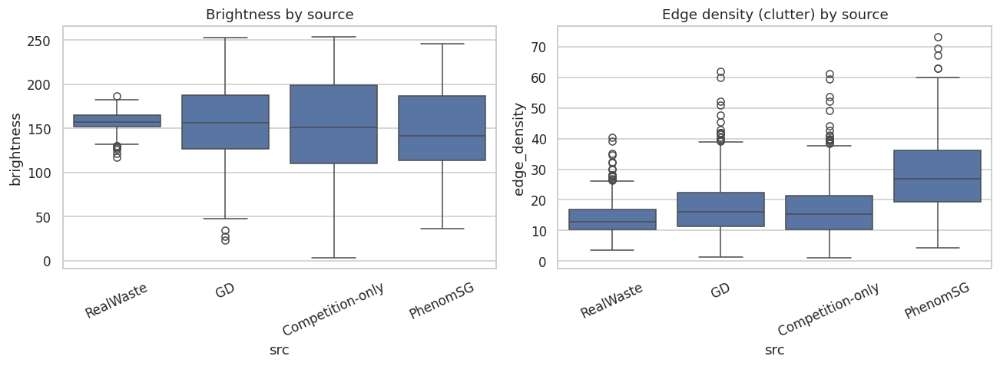

,mean_r,mean_g,mean_b,brightness,edge_density
src,,,,,
RealWaste,156.100006,158.800003,163.000000,157.399994,12.800000
GD,164.899994,154.199997,144.100006,156.300003,16.100000
Competition-only,161.300003,148.699997,137.500000,151.300003,15.300000
PhenomSG,148.899994,141.500000,126.300003,141.800003,26.799999


content (colour, clutter)          source predicted with 58.1% accuracy (chance 25%)
format (size, shape, file size)    source predicted with 73.4% accuracy (chance 25%)
both                               source predicted with 76.3% accuracy (chance 25%)


In [10]:
# ============================================================
# CELL 7 - COLOUR, CLUTTER AND SOURCE-SHORTCUT TEST
# ============================================================
# WHAT: Measure colour, brightness and background clutter per source, then test how easily
#       a trivial classifier can tell the sources apart.
# WHY:  If a few cheap numbers reveal which dataset an image came from, a model can learn
#       the source instead of the waste item. Splitting the cues into "content" (colour,
#       clutter) and "format" (size, shape, file size) shows which kind is the problem and
#       how to fix it (standardise formats, cap sources per class).
# HOW:  Each sampled image is shrunk to 64x64. Edge density (mean absolute difference between
#       neighbouring pixels) is a clutter proxy. A random forest with 5-fold cross-validation
#       predicts the source from each feature group; chance is 25% with 4 balanced sources.
#       Class mix differs by source too, so a high score is a warning, not proof.
# ------------------------------------------------------------------------------------

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

SRC_ORDER = ["RealWaste", "GD", "Competition-only", "PhenomSG"]

def colour_clutter(path, size=(64, 64)):
    with Image.open(path) as img:
        img.draft("RGB", size)
        arr = np.asarray(img.convert("RGB").resize(size), dtype=np.float32)
    r, g, b = arr[..., 0].mean(), arr[..., 1].mean(), arr[..., 2].mean()
    gray = arr.mean(axis=2)
    edge = np.abs(np.diff(gray, axis=0)).mean() + np.abs(np.diff(gray, axis=1)).mean()
    return r, g, b, 0.299 * r + 0.587 * g + 0.114 * b, edge

sample = (uniq.groupby("src", group_keys=False)
              .apply(lambda g: g.sample(min(600, len(g)), random_state=SEED))
              .reset_index(drop=True))

feats = [colour_clutter(p) for p in tqdm(sample["path"], desc="Colour / clutter")]
content_cols = ["mean_r", "mean_g", "mean_b", "brightness", "edge_density"]
sample[content_cols] = pd.DataFrame(feats, index=sample.index)
sample["aspect"] = sample["width"] / sample["height"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=sample, x="src", y="brightness", order=SRC_ORDER, ax=axes[0])
axes[0].set_title("Brightness by source")
sns.boxplot(data=sample, x="src", y="edge_density", order=SRC_ORDER, ax=axes[1])
axes[1].set_title("Edge density (clutter) by source")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

display(sample.groupby("src")[content_cols].median().round(1).loc[SRC_ORDER])

format_cols = ["width", "height", "aspect", "bytes"]
for name, cols in [("content (colour, clutter)", content_cols),
                   ("format (size, shape, file size)", format_cols),
                   ("both", content_cols + format_cols)]:
    acc = cross_val_score(RandomForestClassifier(200, random_state=SEED, n_jobs=-1),
                          sample[cols], sample["src"], cv=5).mean()
    print(f"{name:34s} source predicted with {acc:.1%} accuracy (chance 25%)")

In [11]:
# ============================================================
# CELL 7b - DARK / WHITE BACKGROUND SHARE PER CLASS AND SOURCE
# ============================================================
# WHAT: Show the share of images with a mostly dark or mostly white frame, per class and source.
# WHY:  The grids showed black-background product shots in some classes. If a class is
#       concentrated in one background style, the model can learn the background, not the item.
# HOW:  Mean brightness below 60 is treated as a dark background and above 215 as white. These
#       are rough thresholds, and the sample is small (about 600 per source).
# ------------------------------------------------------------------------------------

sample["dark_bg"] = sample["brightness"] < 60
sample["white_bg"] = sample["brightness"] > 215
for col, name in [("dark_bg", "dark"), ("white_bg", "white")]:
    print(f"Share of images with a {name} background:")
    display(pd.crosstab(sample["final_class"], sample["src"],
                        values=sample[col], aggfunc="mean").round(2))

Share of images with a dark background:


src,Competition-only,GD,PhenomSG,RealWaste
final_class,,,,
food_garden,0.26,0.00,0.01,0.0
general,0.08,0.06,0.01,0.0
glass,0.12,0.01,0.00,0.0
metal,0.07,0.00,0.00,0.0
paper_card,0.05,0.02,0.00,0.0
plastic,0.11,0.01,0.00,0.0
special,0.37,0.00,0.01,NaN
textile,0.07,0.01,NaN,0.0


Share of images with a white background:


src,Competition-only,GD,PhenomSG,RealWaste
final_class,,,,
food_garden,0.04,0.07,0.03,0.0
general,0.48,0.44,0.16,0.0
glass,0.14,0.20,0.22,0.0
metal,0.03,0.11,0.05,0.0
paper_card,0.13,0.20,0.08,0.0
plastic,0.25,0.13,0.10,0.0
special,0.30,0.22,0.15,NaN
textile,0.02,0.05,NaN,0.0


**Finding:** RealWaste is visually narrow: brightness sits tightly around 157 with low clutter (edge density ~13), while GD, the competition and PhenomSG are far more spread (PhenomSG edge density ~27). A random forest given only simple colour/clutter numbers identifies the source **58.1%** of the time (chance 25%), file-format features alone give **73.4%**, and both together **76.3%**. A model can therefore learn "grey concrete means RealWaste class X" instead of learning the waste. Section 7b shows the content shortcut is class-specific: RealWaste has **0%** white or dark backgrounds in every class, while **44–48%** of GD and competition `general` images have a white background and **37%** of competition `special` images have a dark background. Format shortcuts are removed by standardisation (Section 10), colour and lighting shortcuts are reduced by augmentation (Section 13), and any remaining ones are the reason the final test must be real photos (Section 14).

<a id="section-8"></a>
## Section 8: Near-Duplicate Detection

**Goal:** Find images that are the same photo saved at different sizes or compression (not byte-identical, so Section 4 missed them), so they cannot straddle the train/test split.

**Method:** a 64-bit perceptual hash (dHash) finds *candidates*, then a pixel-level comparison *verifies* each candidate.

In [12]:
# ============================================================
# CELL 8a - PERCEPTUAL HASH (dHash) OF EVERY DISTINCT IMAGE
# ============================================================
# WHAT: Compute a 64-bit "difference hash" for each image in the de-duplicated table and
#       save it, so near-duplicates can be found in Cell 8b.
# WHY:  Cell 5 only found byte-identical files. A re-saved, resized or recompressed copy of
#       the same photo has different bytes but nearly the same visual fingerprint. If such
#       copies end up in both train and test, accuracy is inflated.
# HOW:  Each image is shrunk to 9x8 greyscale; each of the 64 bits records whether a pixel
#       is brighter than its right-hand neighbour. Similar-looking images get hashes that
#       differ in only a few bits. img.draft() makes JPEG decoding much faster.
# ------------------------------------------------------------------------------------

uniq = uniq.reset_index(drop=True)      # row i of the table = row i of the hash matrix

def dhash_bits(path, hash_size=8):
    try:
        with Image.open(path) as img:
            img.draft("L", (hash_size * 8, hash_size * 8))
            g = img.convert("L").resize((hash_size + 1, hash_size), Image.LANCZOS)
        a = np.asarray(g, dtype=np.int16)
        return (a[:, 1:] > a[:, :-1]).flatten().astype(np.uint8)
    except Exception:
        return np.zeros(hash_size * hash_size, dtype=np.uint8)

H = np.stack([dhash_bits(p) for p in tqdm(uniq["path"], desc="dHash")])
np.save("/kaggle/working/dhash.npy", H)
print(f"Hash matrix: {H.shape}  |  all-zero hashes (failed reads): {int((H.sum(1) == 0).sum())}")

dHash: 100%|██████████| 23032/23032 [01:21<00:00, 281.12it/s]

Hash matrix: (23032, 64)  |  all-zero hashes (failed reads): 4


Comparing hashes: 100%|██████████| 24/24 [00:05<00:00,  4.50it/s]

Pairs by number of differing bits (out of 64):


,pairs
d,
0,354
1,553
2,954
3,1420
4,2447
5,3786
6,6013
7,9247
8,14358



At THRESH=4: 676 near-duplicate groups, 2,142 images in them, 1,466 would be removed

Near-duplicate pairs by source combination:


,pairs
GD,2370
Competition-only + GD,2290
Competition-only,532
GD + PhenomSG,284
Competition-only + PhenomSG,114
GD + RealWaste,52
PhenomSG,48
RealWaste,27
Competition-only + RealWaste,10
PhenomSG + RealWaste,1


Near-duplicate pairs whose two images have DIFFERENT classes: 3,139


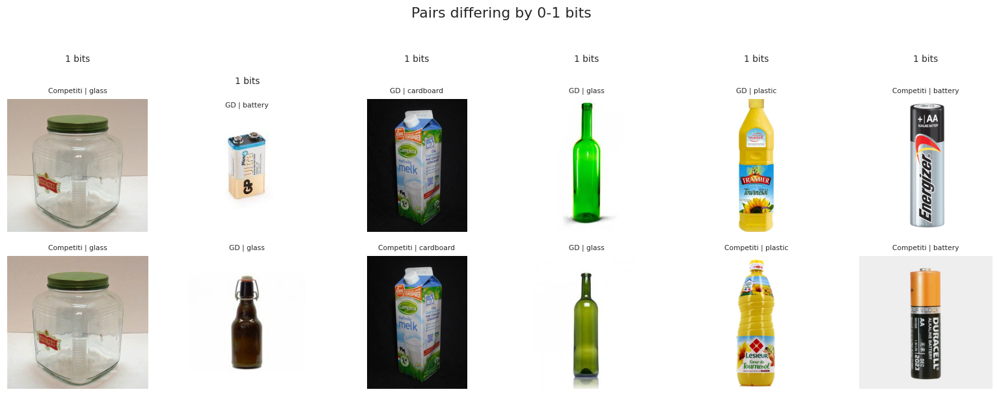

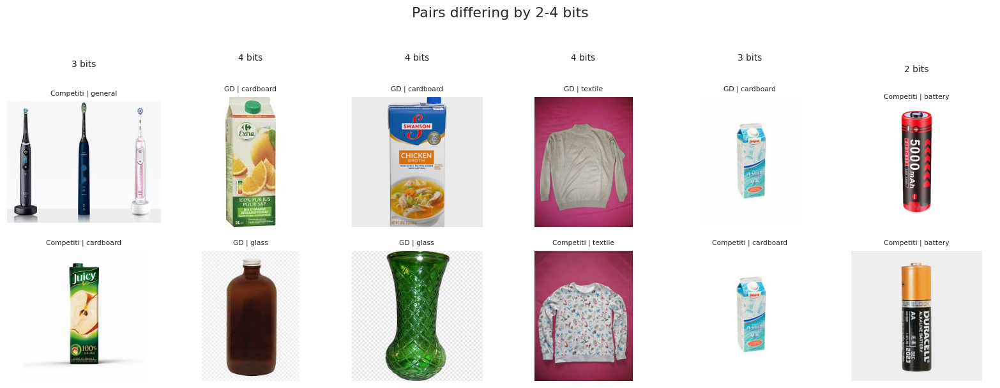

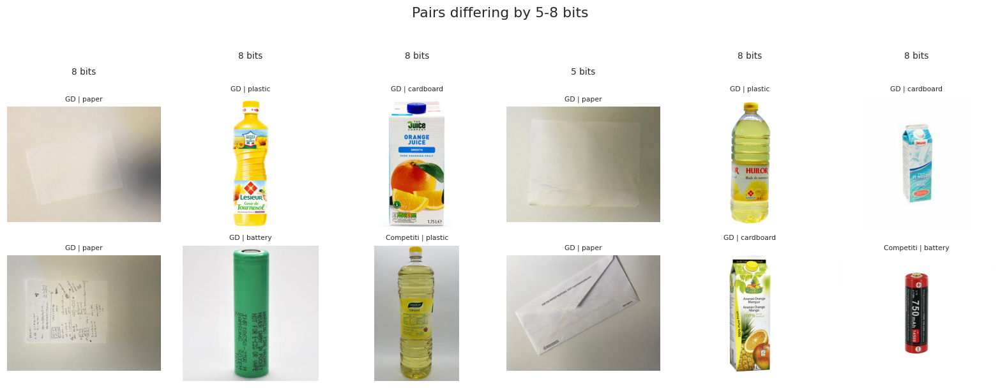

In [13]:
# ============================================================
# CELL 8b - FIND NEAR-DUPLICATE PAIRS, GROUP THEM, AND INSPECT THEM
# ============================================================
# WHAT: Compare every pair of hashes, count pairs by number of differing bits, group images
#       that are near-identical, and show example pairs at several distances.
# WHY:  A threshold that is too loose deletes genuinely different photos (plain backgrounds
#       make unrelated images look alike); too strict leaves copies behind. Looking at real
#       pairs at each distance is how we choose THRESH.
# HOW:  Hamming distance between two 0/1 vectors = bits in a + bits in b - 2 * (a . b), so
#       one matrix multiplication per chunk gives all distances. Connected pairs are merged
#       into groups with union-find. Pairs up to 8 bits are kept for the viewer; THRESH
#       (bits) decides which pairs form groups.
# ------------------------------------------------------------------------------------

THRESH = 4          # pairs differing in <= THRESH of 64 bits count as near-duplicates

Hf = H.astype(np.float32)
pop = Hf.sum(1)
n = len(Hf)
pi, pj, pd_ = [], [], []
for s in tqdm(range(0, n, 1000), desc="Comparing hashes"):
    e = min(s + 1000, n)
    d = np.rint(pop[s:e, None] + pop[None, :] - 2 * (Hf[s:e] @ Hf.T))
    ii, jj = np.nonzero(d <= 8)
    keep = jj > (ii + s)                                  # each pair once, no self-pairs
    pi.append(ii[keep] + s); pj.append(jj[keep]); pd_.append(d[ii[keep], jj[keep]])

pairs = pd.DataFrame({"i": np.concatenate(pi), "j": np.concatenate(pj), "d": np.concatenate(pd_).astype(int)})
print("Pairs by number of differing bits (out of 64):")
display(pairs["d"].value_counts().sort_index().rename("pairs").to_frame())

# --- Union-find: merge pairs at or below THRESH into groups ---
parent = np.arange(n)
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for a, b in pairs.loc[pairs["d"] <= THRESH, ["i", "j"]].itertuples(index=False):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra
uniq["near_group"] = [find(i) for i in range(n)]

sizes = uniq["near_group"].value_counts()
print(f"\nAt THRESH={THRESH}: {int((sizes > 1).sum()):,} near-duplicate groups, "
      f"{int(sizes[sizes > 1].sum()):,} images in them, {int(n - len(sizes)):,} would be removed")

near = pairs[pairs["d"] <= THRESH]
print("\nNear-duplicate pairs by source combination:")
display(pd.Series([" + ".join(sorted({uniq.at[a, "src"], uniq.at[b, "src"]}))
                   for a, b in zip(near["i"], near["j"])]).value_counts().rename("pairs").to_frame())
cross = [(uniq.at[a, "final_class"] if "final_class" in uniq else uniq.at[a, "concept"],
          uniq.at[b, "final_class"] if "final_class" in uniq else uniq.at[b, "concept"])
         for a, b in zip(near["i"], near["j"])]
print(f"Near-duplicate pairs whose two images have DIFFERENT classes: {sum(x != y for x, y in cross):,}")

# --- Viewer: random pairs at several distances ---
def show_pairs(lo, hi, k=6):
    sel = pairs[(pairs["d"] >= lo) & (pairs["d"] <= hi)]
    if sel.empty:
        print(f"No pairs with distance {lo}-{hi}"); return
    sel = sel.sample(min(k, len(sel)), random_state=SEED)
    fig, axes = plt.subplots(2, len(sel), figsize=(len(sel) * 2.4, 5.4), squeeze=False)
    for c, (_, row) in enumerate(sel.iterrows()):
        for r, idx in enumerate((int(row["i"]), int(row["j"]))):
            ax = axes[r, c]; ax.axis("off")
            with Image.open(uniq.at[idx, "path"]) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(f"{uniq.at[idx, 'src'][:9]} | {uniq.at[idx, 'concept']}", fontsize=7)
        axes[0, c].text(0.5, 1.28, f"{int(row['d'])} bits", transform=axes[0, c].transAxes,
                        ha="center", fontsize=9)
    plt.suptitle(f"Pairs differing by {lo}-{hi} bits", y=1.02)
    plt.tight_layout(); plt.show()

show_pairs(0, 1)
show_pairs(2, 4)
show_pairs(5, 8)

**Finding (hash only):** 23,032 images were hashed (4 failed to read). A hash-only rule at 4 differing bits would flag **676 groups** but also **3,139 pairs with different classes**, and the viewers showed many of these were different photos of similar-looking items. A hash alone is too loose for white-background product photos, so candidates are verified in the next step.

Candidate pairs: 15,527 involving 3,362 images


Thumbnails: 100%|██████████| 3362/3362 [00:10<00:00, 315.35it/s]


Candidates and verified pairs by hash distance:


,candidates,verified
d,,
0,354,211
1,553,196
2,954,113
3,1420,65
4,2447,28
5,3786,15
6,6013,10


Verified pairs: 638  |  with DIFFERENT classes: 3


,pairs
Competition-only + GD,507
Competition-only,62
PhenomSG,29
GD,22
GD + PhenomSG,12
Competition-only + PhenomSG,4
RealWaste,2



Groups with copies: 605  |  images in them: 1,227  |  would be removed: 622  |  largest group: 4
Images with failed reads (to drop): 4


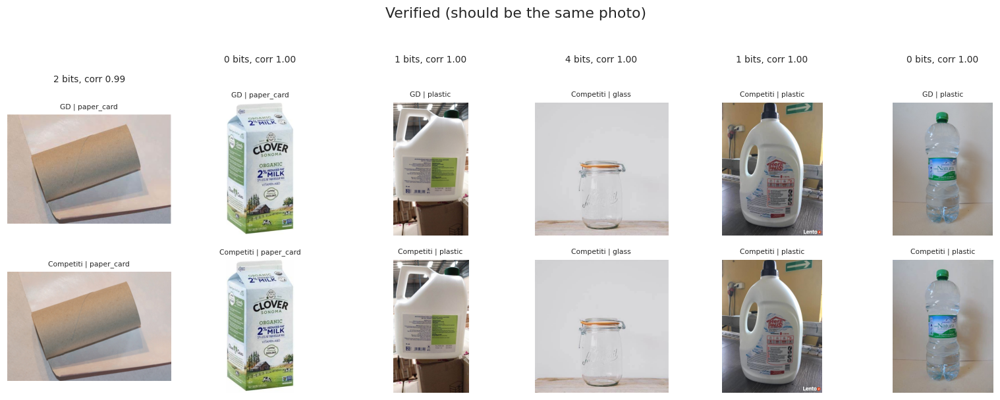

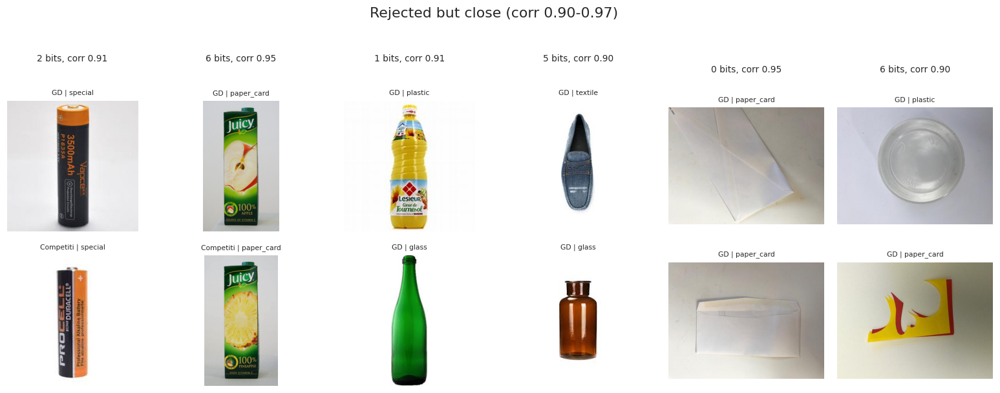

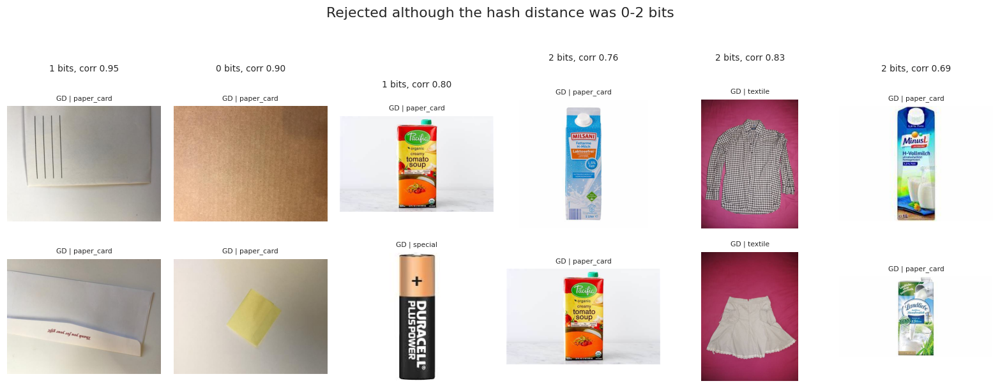

In [14]:
# ============================================================
# CELL 8c - VERIFY NEAR-DUPLICATE CANDIDATES WITH A PIXEL COMPARISON
# ============================================================
# WHAT: Re-check every candidate pair (hash distance <= CAND_BITS) by comparing 32x32
#       greyscale thumbnails and the aspect ratio, and rebuild the duplicate groups from the
#       verified pairs only.
# WHY:  The 64-bit hash is dominated by plain backgrounds, so different white-background
#       products got matched (3,139 of 5,728 pairs at 4 bits linked different classes). A
#       real duplicate or resize looks almost the same pixel for pixel.
# HOW:  Each thumbnail is mean-centred and normalised, so a dot product gives the correlation
#       (1.0 = identical pattern). A pair is verified if correlation >= CORR_MIN and the
#       aspect ratios differ by at most ASPECT_TOL. The viewers show borderline cases so you can
#       judge the threshold by eye. Failed reads (all-zero hash) are flagged.
# ------------------------------------------------------------------------------------

CAND_BITS = 6
CORR_MIN = 0.97
ASPECT_TOL = 0.03

uniq["hash_ok"] = H.sum(axis=1) > 0
cand_pairs = pairs[pairs["d"] <= CAND_BITS].copy()
idx = np.unique(np.concatenate([cand_pairs["i"].values, cand_pairs["j"].values]))
print(f"Candidate pairs: {len(cand_pairs):,} involving {len(idx):,} images")

def thumb(path, size=32):
    try:
        with Image.open(path) as img:
            img.draft("L", (size * 2, size * 2))
            g = img.convert("L").resize((size, size), Image.BILINEAR)
        a = np.asarray(g, dtype=np.float32).ravel()
        a = a - a.mean()
        n = np.linalg.norm(a)
        return a / n if n > 0 else a
    except Exception:
        return np.zeros(size * size, dtype=np.float32)

T = np.stack([thumb(uniq.at[k, "path"]) for k in tqdm(idx, desc="Thumbnails")])
row = {k: r for r, k in enumerate(idx)}
ri, rj = cand_pairs["i"].map(row).values, cand_pairs["j"].map(row).values
cand_pairs["corr"] = np.einsum("ij,ij->i", T[ri], T[rj])

asp = (uniq["width"] / uniq["height"]).values
cand_pairs["asp_diff"] = np.abs(asp[cand_pairs["i"].values] / asp[cand_pairs["j"].values] - 1)
cand_pairs["verified"] = (cand_pairs["corr"] >= CORR_MIN) & (cand_pairs["asp_diff"] <= ASPECT_TOL)

print("Candidates and verified pairs by hash distance:")
display(cand_pairs.groupby("d")["verified"].agg(candidates="size", verified="sum"))

ver = cand_pairs[cand_pairs["verified"]]
cls = uniq["final_class"].values
print(f"Verified pairs: {len(ver):,}  |  with DIFFERENT classes: "
      f"{int((cls[ver['i'].values] != cls[ver['j'].values]).sum()):,}")
display(pd.Series([" + ".join(sorted({uniq.at[a, "src"], uniq.at[b, "src"]}))
                   for a, b in zip(ver["i"], ver["j"])]).value_counts().rename("pairs").to_frame())

# --- Rebuild groups from verified pairs only ---
n = len(uniq)
parent = np.arange(n)
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for a, b in ver[["i", "j"]].itertuples(index=False):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra
uniq["near_group"] = [find(i) for i in range(n)]
sizes = uniq["near_group"].value_counts()
print(f"\nGroups with copies: {int((sizes > 1).sum()):,}  |  images in them: {int(sizes[sizes > 1].sum()):,}"
      f"  |  would be removed: {int(n - len(sizes)):,}  |  largest group: {int(sizes.max())}")
print(f"Images with failed reads (to drop): {int((~uniq['hash_ok']).sum())}")

# --- Viewers: judge the threshold by eye ---
def show_cand(sel, title, k=6):
    if sel.empty:
        print(f"{title}: none"); return
    sel = sel.sample(min(k, len(sel)), random_state=SEED)
    fig, axes = plt.subplots(2, len(sel), figsize=(len(sel) * 2.4, 5.4), squeeze=False)
    for c, (_, r) in enumerate(sel.iterrows()):
        for rr, k_ in enumerate((int(r["i"]), int(r["j"]))):
            ax = axes[rr, c]; ax.axis("off")
            with Image.open(uniq.at[k_, "path"]) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(f"{uniq.at[k_, 'src'][:9]} | {uniq.at[k_, 'final_class']}", fontsize=7)
        axes[0, c].text(0.5, 1.30, f"{int(r['d'])} bits, corr {r['corr']:.2f}",
                        transform=axes[0, c].transAxes, ha="center", fontsize=9)
    plt.suptitle(title, y=1.02); plt.tight_layout(); plt.show()

show_cand(cand_pairs[cand_pairs["verified"]], "Verified (should be the same photo)")
show_cand(cand_pairs[~cand_pairs["verified"] & (cand_pairs["corr"] >= 0.90)], "Rejected but close (corr 0.90-0.97)")
show_cand(cand_pairs[~cand_pairs["verified"] & (cand_pairs["d"] <= 2)], "Rejected although the hash distance was 0-2 bits")

**Finding (verified):** Of **15,527** candidate pairs (up to 6 bits apart) only **638** pass the pixel check (32×32 correlation ≥ 0.97 and matching aspect ratio); at 0 bits just 211 of 354 pass, which shows how many identical hashes are really different white-background photos. Only **3** verified pairs have different classes. The viewers confirm verified pairs are the same photo (resized or recompressed) and rejected pairs are different items (two Juicy cartons, two envelopes). Most verified pairs are again **GD ↔ competition (507)**. In total 605 groups (1,227 images) contain copies, and 622 images are removable. The threshold 0.97 is kept.

<a id="section-9"></a>
## Section 9: Building the Final Dataset & Split

**Goal:** Produce one clean table: verified duplicates removed, PhenomSG excluded, every (class, source) capped so GD cannot dominate, and a stratified 70/15/15 split.

**Decision on RealWaste "Textile Trash".** These 318 images are worn and often dirty clothes, shoes and socks, plus a few masks and rags. In England textile banks take clean, dry, paired items and soiled cloth goes in general waste, but a photo cannot reliably show *how clean* an item is. The classifier should therefore name the **item type** (clothes, shoes, fabric), and the advice step should ask about condition. The switch `MOVE_RW_TEXTILE` is `False` by default (images stay `textile`); set it to `True` to move them to `general`. Cell 9b shows a random sample so the choice can be checked by eye.

In [15]:
# ============================================================
# CELL 9 - FINAL DATASET: VERIFIED DEDUP, CAP PER SOURCE, SPLIT
# ============================================================
# WHAT: Remove failed reads, excluded sources and verified duplicates, cap how many images
#       each source may give each class, then make a stratified 70/15/15 split and save it.
#       An optional switch can move RealWaste's textile images into "general".
# WHY:  (1) Verified copies must not appear on both sides of the split. (2) GD would
#       otherwise dominate several classes, so the model could learn the source.
#       (3) PhenomSG is dropped (watermarked stock images, posters, wrong labels).
#       (4) RealWaste "Textile Trash" is mostly worn clothes, shoes and socks (Cell 9b), so it
#       stays in the textile class by default; condition (clean or soiled) is for the advice
#       step. Set MOVE_RW_TEXTILE = True to treat it as residual waste instead.
#       The val/test sets come from the same mix of sources as training, so they are NOT
#       the real test. Hand-labelled real photos are.
# HOW:  The textile switch runs before de-duplication, so duplicate groups use the
#       corrected class. Groups whose copies carry different classes are dropped. For the
#       rest we keep the best-priority copy (RealWaste first). groupby.head caps images
#       per (class, source). Stratified splits keep class ratios equal in all splits.
# ------------------------------------------------------------------------------------

from sklearn.model_selection import train_test_split

CAP = 1000
DROP_SOURCES = {"PhenomSG"}      # use set() to keep it
DROP_LABELS = set()              # extra sub-folders to exclude
MOVE_RW_TEXTILE = False          # True = move RealWaste Textile Trash to general

if MOVE_RW_TEXTILE:
    is_rw_textile = (uniq["src"] == "RealWaste") & (uniq["concept"] == "textile")
    print(f"RealWaste textile images moved to general: {int(is_rw_textile.sum()):,}")
    uniq.loc[is_rw_textile, "final_class"] = "general"
    uniq.loc[is_rw_textile, "concept"] = "soiled_textile"

keep = uniq["hash_ok"] & ~uniq["src"].isin(DROP_SOURCES) & ~uniq["label"].isin(DROP_LABELS)
work = uniq[keep].copy()
print(f"Step 1, after dropping failed reads and excluded sources: {len(work):,}")

mixed = work.groupby("near_group")["final_class"].nunique()
work = work[~work["near_group"].isin(mixed[mixed > 1].index)]
print(f"Step 2, after dropping mixed-class duplicate groups: {len(work):,}")

work = work.sort_values("prio").drop_duplicates("near_group", keep="first")
print(f"Step 3, after keeping one image per duplicate group: {len(work):,}")

work = work.sample(frac=1, random_state=SEED).groupby(["final_class", "src"]).head(CAP)
print(f"Step 4, after capping at {CAP} per class and source: {len(work):,}")

train, rest = train_test_split(work, test_size=0.30, stratify=work["final_class"],
                               random_state=SEED)
val, test = train_test_split(rest, test_size=0.50, stratify=rest["final_class"],
                             random_state=SEED)
final = pd.concat([train.assign(split="train"), val.assign(split="val"),
                   test.assign(split="test")])
final = final[["path", "final_class", "concept", "label", "src", "split"]]
final.to_csv("/kaggle/working/final_dataset.csv", index=False)

print("\nImages per class and split:")
display(pd.crosstab(final["final_class"], final["split"], margins=True, margins_name="total"))
print("Images per class and source:")
display(pd.crosstab(final["final_class"], final["src"], margins=True, margins_name="total"))
print("Images per source and split:")
display(pd.crosstab(final["src"], final["split"], margins=True, margins_name="total"))
sizes = final["final_class"].value_counts()
print(f"Imbalance ratio (largest / smallest): {sizes.max() / sizes.min():.2f}x")

Step 1, after dropping failed reads and excluded sources: 20,403
Step 2, after dropping mixed-class duplicate groups: 20,403
Step 3, after keeping one image per duplicate group: 19,823
Step 4, after capping at 1000 per class and source: 14,424

Images per class and split:


split,test,train,val,total
final_class,,,,
food_garden,283,1318,282,1883
general,216,1008,216,1440
glass,267,1248,268,1783
metal,282,1313,281,1876
paper_card,324,1513,324,2161
plastic,309,1441,309,2059
special,149,696,150,995
textile,334,1559,334,2227
total,2164,10096,2164,14424


Images per class and source:


src,Competition-only,GD,RealWaste,total
final_class,,,,
food_garden,338,699,846,1883
general,493,452,495,1440
glass,363,1000,420,1783
metal,158,929,789,1876
paper_card,200,1000,961,2161
plastic,138,1000,921,2059
special,240,755,0,995
textile,909,1000,318,2227
total,2839,6835,4750,14424


Images per source and split:


split,test,train,val,total
src,,,,
Competition-only,412,2024,403,2839
GD,1064,4766,1005,6835
RealWaste,688,3306,756,4750
total,2164,10096,2164,14424


Imbalance ratio (largest / smallest): 2.24x


**Finding:** The funnel is 20,403 images after dropping failed reads and PhenomSG, **19,823** after removing verified duplicates, and **14,424** after capping each (class, source) at 1,000. So after cleaning, only 19,823 *distinct* images exist across the three usable sources; a 30,000-image dataset was never reachable with honest data, and the extra GD catalogue images would have added little for real floor photos. The split is **10,096 train / 2,164 val / 2,164 test**. With RealWaste's textile images kept as `textile`, the class sizes are textile 2,227, paper_card 2,161, plastic 2,059, food_garden 1,883, metal 1,876, glass 1,783, general 1,440 and special 995, a largest/smallest ratio of **2.24×**. By source: GD 6,835, RealWaste 4,750, competition 2,839. (If `MOVE_RW_TEXTILE = True`, 318 images move to `general` and the ratio becomes 2.17×.)

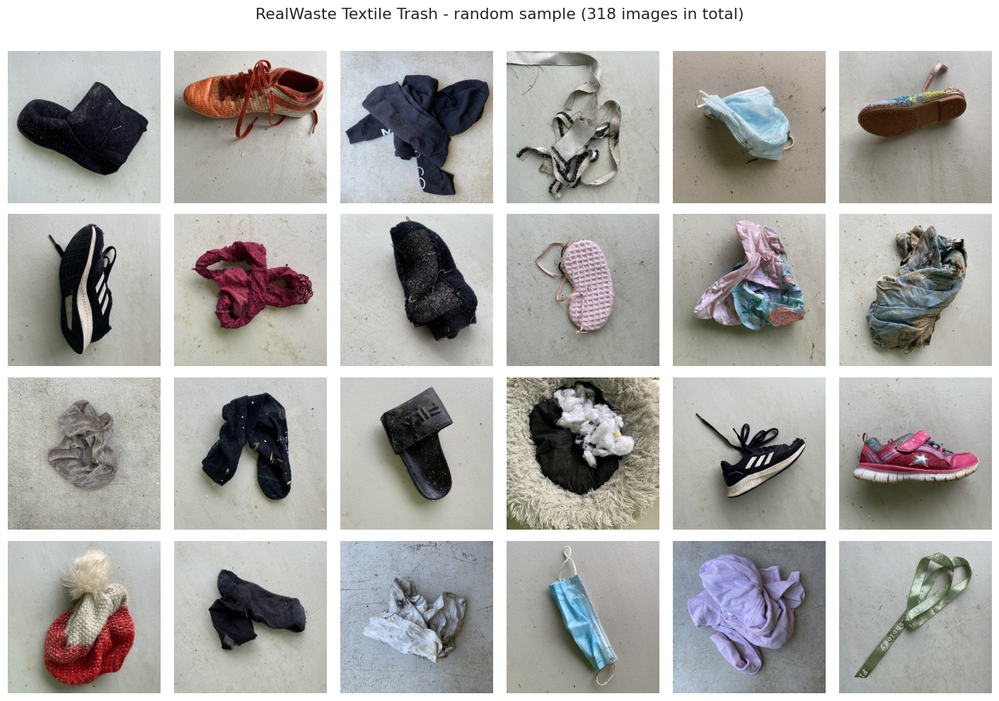

In [16]:
# ============================================================
# CELL 9b - LOOK AT THE REALWASTE TEXTILE IMAGES (JUDGE THE TEXTILE RULE BY EYE)
# ============================================================
# WHAT: Show 24 random RealWaste "Textile Trash" images.
# WHY:  Whether these belong in textile or general is a judgement call. If most are
#       clothes and shoes they stay textile (MOVE_RW_TEXTILE = False in Cell 9); if most are
#       rags, masks and scraps they belong in general (True).
# HOW:  Select by the original folder label (not by class), sample 24, plot a 4 x 6 grid.
# ------------------------------------------------------------------------------------

rw_tex = uniq[(uniq["src"] == "RealWaste") & uniq["label"].str.contains("textile")]
pick = rw_tex.sample(min(24, len(rw_tex)), random_state=SEED)
fig, axes = plt.subplots(4, 6, figsize=(13, 9))
for ax, (_, row) in zip(axes.ravel(), pick.iterrows()):
    ax.imshow(Image.open(row["path"]).convert("RGB")); ax.axis("off")
for ax in axes.ravel()[len(pick):]:
    ax.axis("off")
plt.suptitle(f"RealWaste Textile Trash - random sample ({len(rw_tex)} images in total)", y=1.0)
plt.tight_layout(); plt.show()

**Finding:** In the random sample of 24 RealWaste `Textile Trash` images, about **18 are clothes, shoes, socks or a hat** (many shoes are single trainers, boots and slippers; the clothes are worn, some muddy or holey) and about **6 are face masks, rags, ribbon or a pet-bed lining**. So the class is mostly what a person would call textile, not scrap. Moving all 318 to `general` would mislabel most of them and would also leave `textile` with no real-domain images at all, so they **stay in `textile`**. Whether an item is clean and dry enough for a textile bank is a *condition* a photo cannot show, so it belongs in the advice step (ask the user). The masks and rags are a small amount of label noise; a mask would go in general waste in England. The switch remains in Cell 9 so the effect can be tested.

<a id="section-10"></a>
## Section 10: Standardising the Images

**Goal:** Remove the format shortcut by writing every image in one identical form: a square centre-crop, resized to 224×224, RGB JPEG at quality 95. This is exactly what the Raspberry Pi server will do at inference, so training and deployment see the same pixels.

Standardising: 100%|██████████| 14424/14424 [00:49<00:00, 291.86it/s]


Written: 14,424 images  |  failed: 0
Distinct image sizes in a 300-image sample: {(224, 224)}


,mean,std,min,max
src,,,,
Competition-only,16.2,6.9,1.9,40.9
GD,17.1,7.2,2.8,48.3
RealWaste,23.6,5.3,10.5,39.4


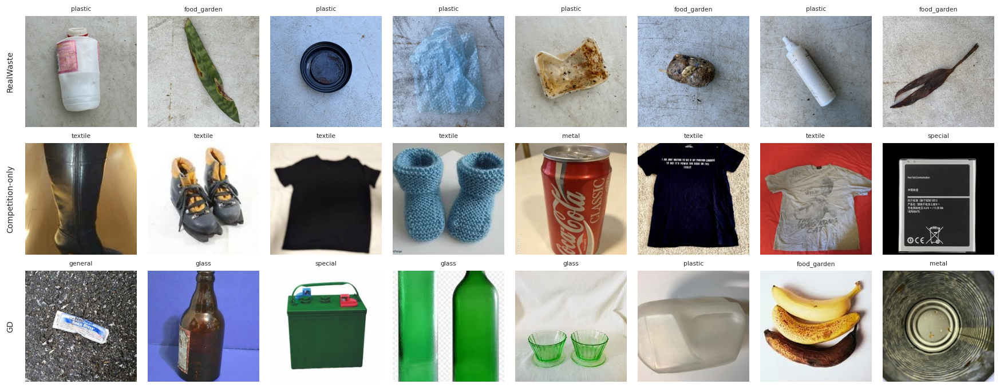

In [17]:
# ============================================================
# CELL 10 - STANDARDISE EVERY IMAGE (CENTRE-CROP, RESIZE, RE-SAVE AS JPEG)
# ============================================================
# WHAT: Write a clean copy of every image in final_dataset.csv: square centre-crop,
#       224x224, RGB, JPEG quality 95, in folders split/class/. Save a new CSV that
#       points at the copies.
# WHY:  The sources differ in format (PNG vs JPEG), size and shape. In Cell 7 a random
#       forest could name the source from these properties alone (73% vs 25% chance),
#       so a model could learn the file type instead of the waste. One standard output
#       removes that shortcut. The centre-crop + 224 resize is exactly what the Pi
#       server will do at inference, so training and deployment see the same pixels.
# HOW:  Open, convert to RGB, crop the middle square, resize with LANCZOS, save as JPEG.
#       A thread pool runs 4 images at a time (decoding releases Python's GIL).
# NOTE: Centre-cropping trims the edges of wide images (some GD photos). That is the
#       same trim the Pi applies, so it is intended.
# ------------------------------------------------------------------------------------

import shutil
from concurrent.futures import ThreadPoolExecutor

OUT = Path("/kaggle/working/verde_std")
shutil.rmtree(OUT, ignore_errors=True)   # no stale files from earlier runs
SIZE, QUALITY = 224, 95

final = pd.read_csv("/kaggle/working/final_dataset.csv")

def standardise(args):
    idx, row = args
    dst = OUT / row.split / row.final_class / f"{row.src.replace(' ', '')}_{idx:05d}.jpg"
    try:
        with Image.open(row.path) as im:
            im = im.convert("RGB")
            w, h = im.size
            s = min(w, h)
            left, top = (w - s) // 2, (h - s) // 2
            im = im.crop((left, top, left + s, top + s)).resize((SIZE, SIZE), Image.LANCZOS)
            dst.parent.mkdir(parents=True, exist_ok=True)
            im.save(dst, "JPEG", quality=QUALITY)
        return str(dst)
    except Exception:
        return None

with ThreadPoolExecutor(max_workers=4) as ex:
    new_paths = list(tqdm(ex.map(standardise, final.iterrows()),
                          total=len(final), desc="Standardising"))

final["std_path"] = new_paths
failed = final["std_path"].isna().sum()
final = final.dropna(subset=["std_path"]).reset_index(drop=True)
final.to_csv("/kaggle/working/final_dataset_std.csv", index=False)
print(f"Written: {len(final):,} images  |  failed: {failed}")

# --- Sanity check 1: every copy has identical size and format ---
chk = final.sample(300, random_state=SEED)
shapes = {Image.open(p).size for p in chk["std_path"]}
print("Distinct image sizes in a 300-image sample:", shapes)

# --- Sanity check 2: does file size still reveal the source? ---
final["kb"] = [Path(p).stat().st_size / 1024 for p in final["std_path"]]
display(final.groupby("src")["kb"].describe()[["mean", "std", "min", "max"]].round(1))

# --- Sanity check 3: look at 8 random images per source ---
srcs = final["src"].unique()
fig, axes = plt.subplots(len(srcs), 8, figsize=(16, 2.1 * len(srcs)))
for r, s in enumerate(srcs):
    pick = final[final["src"] == s].sample(8, random_state=SEED)
    for c, (_, row) in enumerate(pick.iterrows()):
        axes[r, c].imshow(Image.open(row.std_path)); axes[r, c].axis("off")
        axes[r, c].set_title(row.final_class, fontsize=7)
    axes[r, 0].text(-0.1, 0.5, s, transform=axes[r, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=9)
plt.tight_layout(); plt.show()

**Finding:** All **14,424** images were written with **0 failures** and a 300-image sample is all 224×224, so size, shape and format no longer identify the source (this removes the 73.4% format shortcut from Section 7 by construction). The remaining file-size gap (RealWaste ~23.6 KB, GD ~17.1 KB, competition ~16.2 KB) is image *content*: the textured concrete floor compresses less than plain studio backgrounds, which is the same background difference seen in Section 7. Centre-cropping trims the edges of wide images; the Pi applies the same crop.

<a id="section-11"></a>
## Section 11: Class Distribution

**Goal:** Chart how large each class is, where its images come from, and check that train, validation and test keep the same class proportions. Compute the class weights the training run will use.

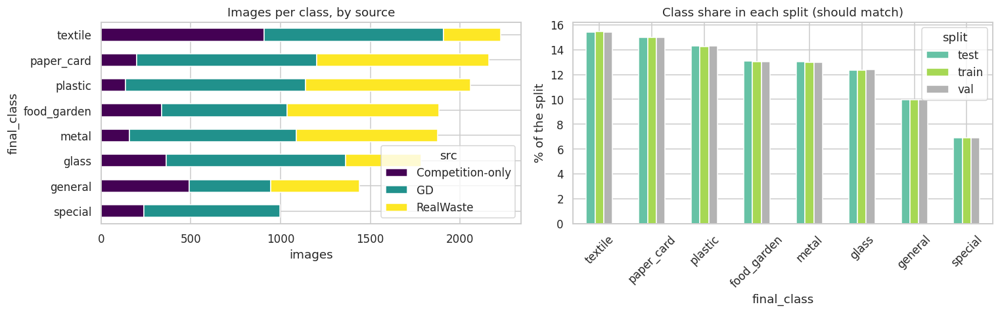

Imbalance ratio (largest/smallest): 2.24x
Max difference in a class's share between splits (percentage points): 0.05


,train_images,class_weight
final_class,,
textile,1559,0.809
paper_card,1513,0.834
plastic,1441,0.876
food_garden,1318,0.958
metal,1313,0.961
glass,1248,1.011
general,1008,1.252
special,696,1.813


In [18]:
# ============================================================
# CELL 11 - CLASS DISTRIBUTION OF THE FINAL DATASET
# ============================================================
# WHAT: Chart how many images each of the 8 classes has, how much of each class comes from
#       each source, and confirm the train/val/test split keeps the same proportions.
#       Compute class weights for training.
# WHY:  A model learns what it sees most. If one source supplies most of a class, the model
#       learns that source's style (Cell 7b showed backgrounds differ by source). The split
#       must keep class proportions so validation and test scores mean the same thing.
# HOW:  Stacked bar of class x source, a proportion table per split, and the balanced
#       class weights formula n_total / (n_classes x n_class).
# ------------------------------------------------------------------------------------

final = pd.read_csv("/kaggle/working/final_dataset_std.csv")
order = final["final_class"].value_counts().index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ct = pd.crosstab(final["final_class"], final["src"]).loc[order]
ct.plot(kind="barh", stacked=True, ax=axes[0], colormap="viridis")
axes[0].invert_yaxis(); axes[0].set_xlabel("images"); axes[0].set_title("Images per class, by source")

share = pd.crosstab(final["final_class"], final["split"], normalize="columns").loc[order] * 100
share.plot(kind="bar", ax=axes[1], colormap="Set2")
axes[1].set_ylabel("% of the split"); axes[1].set_title("Class share in each split (should match)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

counts = final.loc[final["split"] == "train", "final_class"].value_counts()
weights = (counts.sum() / (len(counts) * counts)).round(3).rename("class_weight")
print(f"Imbalance ratio (largest/smallest): {counts.max() / counts.min():.2f}x")
print("Max difference in a class's share between splits (percentage points): "
      f"{(share.max(axis=1) - share.min(axis=1)).max():.2f}")
display(pd.concat([counts.rename("train_images"), weights], axis=1).loc[order])

**Finding:** The class imbalance is **2.24×** (textile 1,559 down to special 696 training images), which is mild enough to handle with class weights (**0.81 for textile to 1.81 for special**) rather than discarding data. Class shares differ by at most **0.05 percentage points** between train, val and test. The stacked bars show a source problem: **`special` has no RealWaste images at all**, and `textile` has only 318, so their examples are mostly catalogue-style photos. A model could learn "studio background means special" and never predict it for a real floor photo.

<a id="section-12"></a>
## Section 12: Class Similarity & the Domain Gap

**Goal:** Measure (a) which classes look alike, (b) how well a simple nearest-class rule separates them, and (c) how different the sources are from each other, using frozen MobileNetV2 features (no training involved). This is a diagnostic *floor*, not a model score.

In [19]:
# ============================================================
# CELL 12a - EXTRACT MobileNetV2 FEATURES FOR EVERY IMAGE
# ============================================================
# WHAT: Turn each standardised image into a 1,280-number feature vector using a MobileNetV2
#       pretrained on ImageNet.
# WHY:  Features let us measure how similar classes and sources look without training our own
#       model, as in version 1 (Section 8). Computed once here and reused in Cell 12b.
# HOW:  Load the weights, drop the classifier, global-average-pool the last feature map, run
#       in batches on the GPU with a progress bar, and save the array.
# ------------------------------------------------------------------------------------

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", dev)

norm = transforms.Compose([transforms.ToTensor(),
                           transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

class Imgs(Dataset):
    def __init__(self, paths): self.paths = list(paths)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return norm(Image.open(self.paths[i]).convert("RGB"))

net = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1).features.to(dev).eval()
pool = nn.AdaptiveAvgPool2d(1)

loader = DataLoader(Imgs(final["std_path"]), batch_size=128, num_workers=2)
feats = []
with torch.no_grad():
    for x in tqdm(loader, desc="Extracting features"):
        feats.append(pool(net(x.to(dev))).flatten(1).cpu().numpy())
F = np.concatenate(feats)
F = F / np.linalg.norm(F, axis=1, keepdims=True)         # unit length -> dot product = cosine
np.save("/kaggle/working/features_std.npy", F)
print("Features:", F.shape)

Device: cuda
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 116MB/s] 
Extracting features: 100%|██████████| 113/113 [00:18<00:00,  6.02it/s]


Features: (14424, 1280)


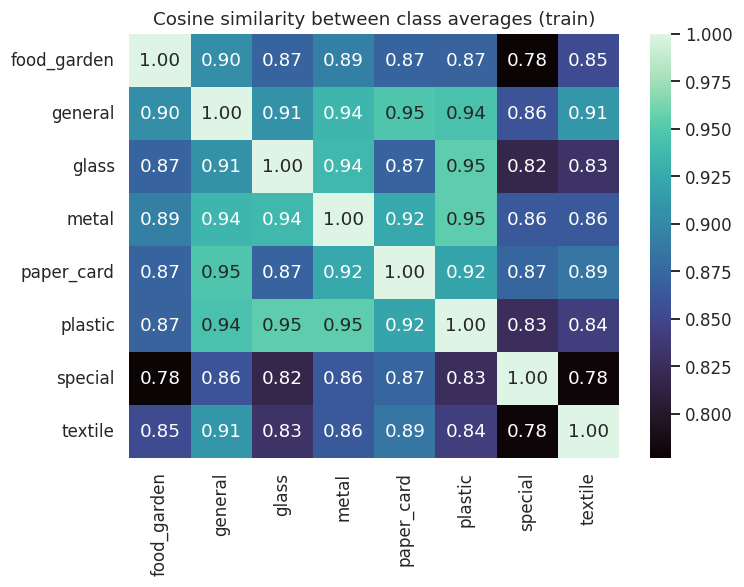

Overall nearest-class accuracy (val): 0.736


,nearest_class_acc
food_garden,0.961
general,0.579
glass,0.646
metal,0.662
paper_card,0.744
plastic,0.602
special,0.913
textile,0.820


Most common confusions (true -> predicted):


,true,pred,images
0,plastic,glass,54
1,glass,plastic,44
2,paper_card,general,44
3,glass,metal,35
4,textile,general,35
5,general,paper_card,28
6,plastic,metal,24
7,plastic,paper_card,24


Cross-source test (only classes present in both sources):


,centroids from -> tested on,classes,val images,accuracy
0,RealWaste -> GD+Competition,7,1258,0.614
1,GD+Competition -> RealWaste,7,756,0.459
2,RealWaste -> RealWaste (same source),7,756,0.664
3,GD+Competition -> GD+Competition (same source),7,1258,0.819


In [20]:
# ============================================================
# CELL 12b - CLASS SIMILARITY, NEAREST-CLASS TEST AND CROSS-SOURCE TEST
# ============================================================
# WHAT: (1) How similar are class "averages" to each other? (2) If we label each validation
#       image by the nearest class average from the training images, how often is that
#       right, per class? (3) Do class averages learned from one source also work on another?
# WHY:  (1)-(2) show which classes are naturally confusable, so we know where the model will
#       struggle (paper_card vs general, for example). (3) is the domain-gap test: RealWaste
#       is the only real floor-photo source, so if averages from RealWaste do not work on GD
#       and the competition images (and the reverse), the sources are visually different
#       worlds and mixing them is a risk.
# HOW:  Centroid = mean feature of a class's training images. Predict by highest cosine
#       similarity to a centroid. For (3), build centroids from one source and classify the
#       other source's validation images, using only classes both sources contain.
# ------------------------------------------------------------------------------------

classes = sorted(final["final_class"].unique())
y = final["final_class"].values
tr, va = (final["split"] == "train").values, (final["split"] == "val").values

def centroids(mask, labels):
    C = np.stack([F[mask & (y == c)].mean(axis=0) for c in labels])
    return C / np.linalg.norm(C, axis=1, keepdims=True)

def nearest(Cmat, labels, idx):
    return np.array(labels)[(F[idx] @ Cmat.T).argmax(axis=1)]

# (1) class-to-class similarity
C_all = centroids(tr, classes)
plt.figure(figsize=(7, 5.5))
sns.heatmap(C_all @ C_all.T, annot=True, fmt=".2f", cmap="mako",
            xticklabels=classes, yticklabels=classes)
plt.title("Cosine similarity between class averages (train)"); plt.tight_layout(); plt.show()

# (2) nearest-class accuracy on validation images
pred = nearest(C_all, classes, va)
acc = pd.Series(pred == y[va]).groupby(y[va]).mean().rename("nearest_class_acc").round(3)
print(f"Overall nearest-class accuracy (val): {np.mean(pred == y[va]):.3f}")
display(acc.to_frame())
print("Most common confusions (true -> predicted):")
conf = pd.crosstab(pd.Series(y[va], name="true"), pd.Series(pred, name="pred"))
pairs_ = [(a, b, conf.loc[a, b]) for a in conf.index for b in conf.columns if a != b]
display(pd.DataFrame(sorted(pairs_, key=lambda t: -t[2])[:8], columns=["true", "pred", "images"]))

# (3) cross-source test
real = (final["src"] == "RealWaste").values
other = (~real)
shared = sorted(set(y[real]) & set(y[other]))
rows = []
for name, a_mask, b_mask in [("RealWaste -> GD+Competition", real, other),
                             ("GD+Competition -> RealWaste", other, real),
                             ("RealWaste -> RealWaste (same source)", real, real),
                             ("GD+Competition -> GD+Competition (same source)", other, other)]:
    C = centroids(tr & a_mask, shared)
    idx = va & b_mask & np.isin(y, shared)
    rows.append({"centroids from -> tested on": name, "classes": len(shared),
                 "val images": int(idx.sum()),
                 "accuracy": round(float(np.mean(nearest(C, shared, idx) == y[idx])), 3)})
print("Cross-source test (only classes present in both sources):")
display(pd.DataFrame(rows))

**Finding:** Nearest-class accuracy on frozen features is **73.6%**. The distinct classes are `food_garden` (96%), `special` (91%) and `textile` (82%); the weak ones are `general` (58%), `plastic` (60%), `glass` (65%) and `metal` (66%), with `paper_card` at 74%. The heatmap shows plastic, glass and metal at 0.94–0.95 similarity with each other, and `general` close to everything (0.90–0.95) because it is a catch-all. The largest confusions are plastic→glass (54 images), glass→plastic (44), paper_card→general (44), glass→metal (35) and textile→general (35). **Cross-source test (7 shared classes, chance 14%):** class averages from RealWaste classify GD+competition at **61.4%** and the reverse at **45.9%**, against **66.4%** and **81.9%** inside each source. Each source loses about **20 points** on the other, so the sources are visually different worlds. Catalogue-style images transfer worst to real photos, and RealWaste is the harder source (66% against 82% on its own). Validation accuracy on this mix will therefore flatter a model compared with real photos.

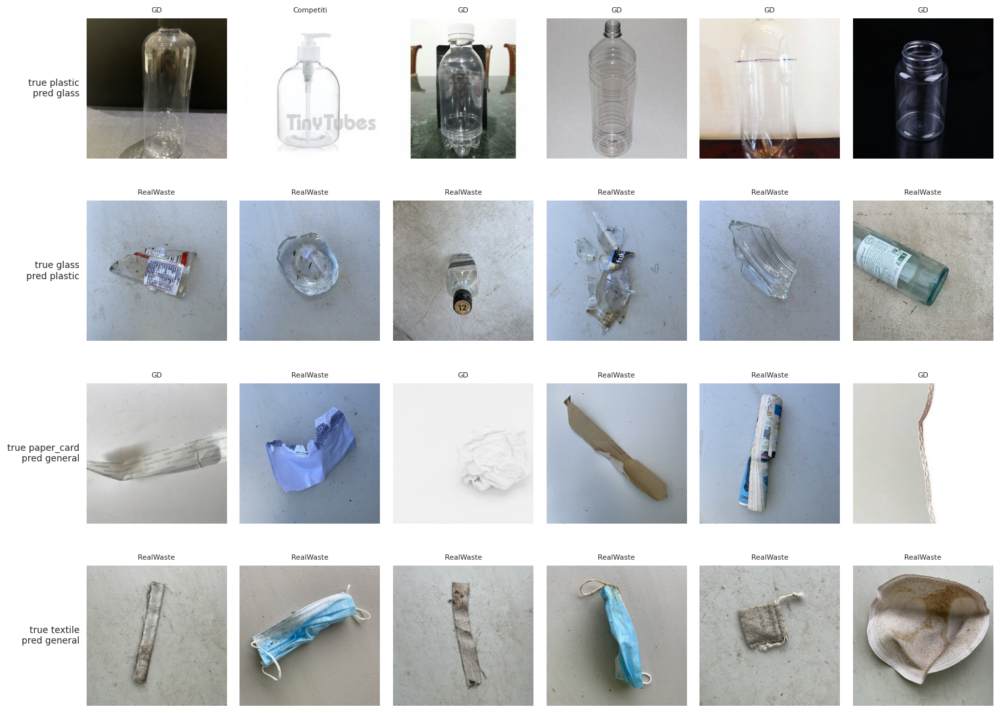

In [21]:
# ============================================================
# CELL 12c - LOOK AT THE MOST CONFUSED VALIDATION IMAGES
# ============================================================
# WHAT: For the main confused pairs from Cell 12b, show the validation images that the
#       nearest-class test got most confidently wrong.
# WHY:  Confusion has three causes: a weak method (frozen features), noisy labels, and truly
#       ambiguous items. Only looking tells us which, and what to clean.
# HOW:  margin = similarity to the predicted class minus similarity to the true class; the
#       largest margins are the most confident mistakes. Shows 6 per pair, with source.
# ------------------------------------------------------------------------------------

va_df = final[va].reset_index(drop=True)
S = F[va] @ C_all.T
cidx = {c: i for i, c in enumerate(classes)}
true_i = va_df["final_class"].map(cidx).values
pred_i = S.argmax(axis=1)
va_df["margin"] = S[np.arange(len(S)), pred_i] - S[np.arange(len(S)), true_i]
va_df["pred"] = np.array(classes)[pred_i]

pairs_to_view = [("plastic", "glass"), ("glass", "plastic"),
                 ("paper_card", "general"), ("textile", "general")]
fig, axes = plt.subplots(len(pairs_to_view), 6, figsize=(14, 2.6 * len(pairs_to_view)))
for r, (a, b) in enumerate(pairs_to_view):
    sel = va_df[(va_df["final_class"] == a) & (va_df["pred"] == b)].nlargest(6, "margin")
    for c in range(6):
        axes[r, c].axis("off")
        if c < len(sel):
            row = sel.iloc[c]
            axes[r, c].imshow(Image.open(row.std_path))
            axes[r, c].set_title(f"{row.src[:9]}", fontsize=7)
    axes[r, 0].text(-0.05, 0.5, f"true {a}\npred {b}", transform=axes[r, 0].transAxes,
                    ha="right", va="center", fontsize=9)
plt.tight_layout(); plt.show()

**Finding:** Most confusion is genuine visual ambiguity, not mislabelling. Clear PET bottles labelled `plastic` look like glass; broken glass shards on the floor look like clear plastic; crumpled paper looks like litter; and in `textile` the images mistaken for `general` are soiled strips of cloth and used face masks (the RealWaste part of the class). A few images are mislabelled or nearly empty (a thin strip, a wrapper filed as paper), which is a small amount of label noise. These pairs cannot be fixed by cleaning alone: fine-tuning learns cues the frozen test cannot, but residual plastic/glass/metal confusion should be expected. Mitigations are in Section 13.

<a id="section-13"></a>
## Section 13: Augmentation & Preprocessing Recommendations

**Goal:** Fix the exact preprocessing and augmentation pipelines for training, and show what the augmentation does to real images.

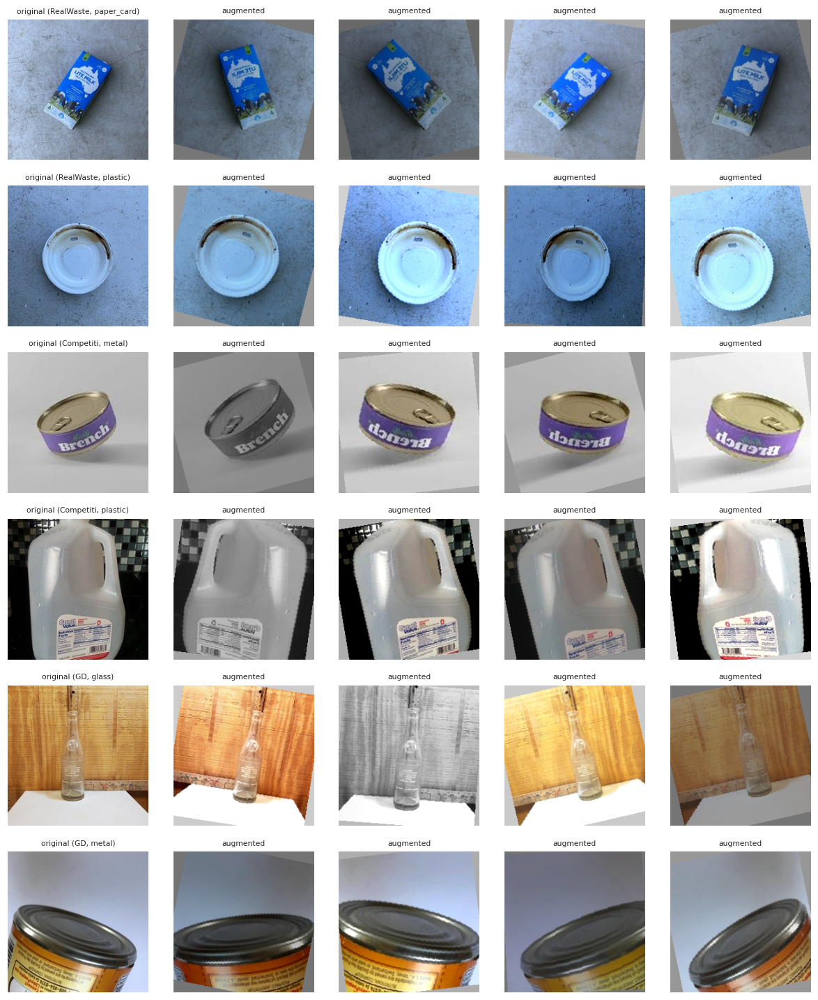

Train transform:
 Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.7, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=160)
    ColorJitter(brightness=(0.65, 1.35), contrast=(0.7, 1.3), saturation=(0.7, 1.3), hue=(-0.03, 0.03))
    RandomGrayscale(p=0.1)
)


In [22]:
# ============================================================
# CELL 13 - AUGMENTATION PREVIEW AND THE FINAL PREPROCESSING PIPELINES
# ============================================================
# WHAT: Define the training and evaluation transforms and show 6 training images next to
#       4 augmented versions of each.
# WHY:  Cell 7b and Cell 12b show the model can latch onto source style (background,
#       lighting, texture) and that sources differ by about 20 points. Augmentation that
#       varies lighting, colour, zoom and angle makes those cues less reliable. Zoom also
#       covers the Pi's varying item distance. Validation/test are NOT augmented, so scores
#       stay comparable.
# HOW:  torchvision transforms on the 224x224 images. Rotation uses fill=160 (mid-grey, as
#       checked in version 1) instead of black corners. RandomGrayscale occasionally removes
#       colour cues entirely.
# ------------------------------------------------------------------------------------

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15, fill=160),
    transforms.ColorJitter(brightness=0.35, contrast=0.3, saturation=0.3, hue=0.03),
    transforms.RandomGrayscale(p=0.1),
])
to_tensor_norm = transforms.Compose([transforms.ToTensor(),
                                     transforms.Normalize([0.485, 0.456, 0.406],
                                                          [0.229, 0.224, 0.225])])
# evaluation pipeline = to_tensor_norm only (images are already centre-cropped to 224)

trn = final[final["split"] == "train"]
pick = pd.concat([trn[trn["src"] == s].sample(2, random_state=SEED) for s in trn["src"].unique()])

fig, axes = plt.subplots(len(pick), 5, figsize=(11, 2.2 * len(pick)))
for r, (_, row) in enumerate(pick.iterrows()):
    img = Image.open(row.std_path).convert("RGB")
    axes[r, 0].imshow(img); axes[r, 0].set_title(f"original ({row.src[:9]}, {row.final_class})", fontsize=7)
    for c in range(1, 5):
        axes[r, c].imshow(train_tf(img)); axes[r, c].set_title("augmented", fontsize=7)
    for c in range(5): axes[r, c].axis("off")
plt.tight_layout(); plt.show()
print("Train transform:\n", train_tf)

**Finding:** The preview shows realistic variation: lighting and colour shifts, mild zoom (so the item is not always the same size, which covers the Pi's varying distance), small rotations with a neutral grey fill (no black corners), mirror flips, and occasional greyscale to weaken colour shortcuts. Validation and test images are *not* augmented.

### Preprocessing Recommendations Summary

| Decision | Rationale | Evidence |
|---|---|---|
| Use 8 UK-oriented classes | Errors that cost the user nothing (paper vs cardboard) are merged; `special` = not for bins | Sections 5, 14 |
| Exclude PhenomSG | Stock photos, posters, watermarks, wrong labels | Section 6 |
| Use verified near-duplicate removal | Prevents the same photo in train and test | Sections 4, 8 |
| Cap 1,000 per (class, source) | Stops GD dominating classes | Sections 9, 11 |
| Standardise to centre-crop 224×224 JPEG q95 | Removes the format shortcut and matches the Pi pipeline | Sections 7, 10 |
| Stratified 70/15/15 split | Same class ratios in every split | Sections 9, 11 |
| Class weights + label smoothing (0.1) | Imbalance 2.24×; plastic/glass/metal ambiguity | Sections 11, 12 |
| Training augmentation as in Cell 13 | Weakens lighting/background shortcuts, adds scale variation | Sections 7, 13 |
| Report **per-source** and **bin-level** accuracy | Pooled accuracy hides the 20-point domain gap | Section 12 |
| Evaluate on hand-labelled Pi photos | Dataset val/test are catalogue-heavy and flatter the model | Sections 12, 14 |

<a id="section-14"></a>
## Section 14: Limitations & Link to VERDE

**Goal:** State what this dataset can and cannot support, and how it feeds the next stage of VERDE.

**Limitations**
- **Domain gap.** Only RealWaste resembles the Pi camera's view (floor photos of real discarded items); GD and the competition are mostly catalogue/phone photos. The two groups lose about 20 points on each other (Section 12), so validation accuracy on this dataset is **not** real-world accuracy.
- **Almost no real photos for `special` and `textile`.** `special` has none and `textile` only RealWaste's 318 worn items (the rest are catalogue shots). Real Pi photos of clean clothes/shoes and batteries/small electricals must be captured and added to training, not only to the test set.
- **Background shortcuts remain.** Format is standardised, but white/dark backgrounds are class-specific in GD and the competition (Section 7b). Augmentation reduces this; it does not remove it.
- **Textile is judged by type, not condition.** RealWaste textile is mostly worn clothes and shoes with a few masks and rags (Cell 9b). The classifier cannot see whether an item is clean and dry enough for a textile bank, so the advice step must ask. `MOVE_RW_TEXTILE` can test the alternative.
- **Source origins.** The competition is largely a re-split of GD (Section 4) and contains RealWaste photos; the licence terms of RealWaste (CC BY-NC-SA 4.0 per IEEE DataPort) restrict commercial use. Fine for a university project, to be re-checked for any deployment.
- **England only.** Class meanings follow England's household rules; councils differ.
- **Ambiguous pairs.** Clear plastic vs glass and crumpled paper vs litter are visually hard; a low-confidence fallback to "general waste / check locally" is needed in the app.

**Link to VERDE.** The next stage is a controlled comparison: **A** RealWaste only, **B** RealWaste + GD + competition, and **leave-one-source-out** runs, all fine-tuning MobileNetV3-Small with class weights and label smoothing, and all scored on hand-labelled photos taken with the Raspberry Pi camera (split by physical item). The best model is exported to ExecuTorch for the Pi; the Llama 3.2 1B step turns the predicted class and the user's council into disposal advice.

In [23]:
# ============================================================
# CELL 14 - SAVE THE DATASET CARD AND PORTABLE PATHS FOR THE TRAINING NOTEBOOK
# ============================================================
# WHAT: Add a portable "rel_path" column to final_dataset_std.csv, write dataset_card.json
#       (class order, class weights, image size, normalisation) and zip the image folder.
# WHY:  std_path holds absolute /kaggle/working/... paths that do not exist in another
#       notebook. rel_path (split/class/file.jpg) works from any root. The training notebook
#       must also use exactly this class order and these weights, otherwise predictions
#       would map to the wrong class names. The zip is a fallback if the image folder is
#       awkward to attach as input.
# HOW:  Strip the working-directory prefix from std_path. Class order = alphabetical (same
#       rule as the baseline). Weights = n_total / (n_classes x n_class) on the training split.
# ------------------------------------------------------------------------------------

import json, shutil

final = pd.read_csv("/kaggle/working/final_dataset_std.csv")
final["rel_path"] = final["std_path"].str.replace("/kaggle/working/verde_std/", "", regex=False)
final.to_csv("/kaggle/working/final_dataset_std.csv", index=False)

classes = sorted(final["final_class"].unique())
counts = final.loc[final["split"] == "train", "final_class"].value_counts()
weights = [round(float(counts.sum() / (len(counts) * counts[c])), 4) for c in classes]

card = {"classes": classes, "class_weights": weights, "image_size": 224,
        "mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225],
        "csv": "final_dataset_std.csv", "image_dir": "verde_std",
        "path_column": "rel_path (join with image_dir)",
        "train": int((final["split"] == "train").sum()),
        "val": int((final["split"] == "val").sum()),
        "test": int((final["split"] == "test").sum())}
with open("/kaggle/working/dataset_card.json", "w") as f:
    json.dump(card, f, indent=2)

shutil.make_archive("/kaggle/working/verde_std", "zip", "/kaggle/working/verde_std")
print("Saved: final_dataset_std.csv, dataset_card.json, verde_std/, verde_std.zip")
print(final[["rel_path", "final_class", "split"]].head(3).to_string(index=False))
print(json.dumps(card, indent=2))

Saved: final_dataset_std.csv, dataset_card.json, verde_std/, verde_std.zip
                                rel_path final_class split
         train/glass/RealWaste_00000.jpg       glass train
train/plastic/Competition-only_00001.jpg     plastic train
          train/food_garden/GD_00002.jpg food_garden train
{
  "classes": [
    "food_garden",
    "general",
    "glass",
    "metal",
    "paper_card",
    "plastic",
    "special",
    "textile"
  ],
  "class_weights": [
    0.9575,
    1.252,
    1.0112,
    0.9612,
    0.8341,
    0.8758,
    1.8132,
    0.8095
  ],
  "image_size": 224,
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ],
  "csv": "final_dataset_std.csv",
  "image_dir": "verde_std",
  "path_column": "rel_path (join with image_dir)",
  "train": 10096,
  "val": 2164,
  "test": 2164
}
